# Research Paper Answer Bot

A retrieval-augmented generation (RAG) system over 11 seminal Generative AI papers. A question in plain language gets an answer written only from the papers, with the top 3 supporting passages cited by paper title and page number.

| Step | Section | Status |
|---|---|---|
| 1 | Setup and configuration | done |
| 2 | Data loading and inspection | done |
| 3 | Chunking experiments | done |
| 4 | Embedding model comparison | done |
| 5 | Vector database build | done |
| 6 | Retrieval strategy comparison | done |
| 7 | RAG pipeline construction | next milestone |
| 8 | Evaluation and failure analysis | |
| 9 | Stretch goals | |
| 10 | Final demo | |
| 11 | Experiment summary and conclusions | |

All pipeline logic lives in the `rpab` package under `backend/`; this notebook imports it, runs each step, and records the observations and decisions.

## 1. Setup and configuration

**Intent.** Make every run repeatable: one configuration object, fixed random seeds, and a switch that decides whether slow experiments are recomputed or loaded from `artifacts/`.

In [1]:
import logging
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))  # the notebook runs from backend/notebooks
logging.getLogger("pypdf").setLevel(logging.ERROR)  # hide pypdf's per-page font warnings

import matplotlib.pyplot as plt
import pandas as pd

from rpab.config import CONFIG
from rpab.utils import set_seed

set_seed(CONFIG.seed)

# True recomputes slow experiments (about 3 minutes for the loader comparison);
# False loads their saved results from artifacts/ when they exist.
RUN_EXPERIMENTS = False

pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 90)

# Chart style. Single-series charts use one hue; comparisons use a fixed
# categorical order that passes colour-vision-deficiency checks.
SERIES = ["#2a78d6", "#eb6834", "#1baf7a"]
SURFACE, INK, INK_2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e7e6e2"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110, "font.size": 10,
    "axes.edgecolor": "#c9c8c3", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "text.color": INK, "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2,
    "legend.frameon": False,
})

pd.DataFrame({
    "setting": ["seed", "pdf_loader", "chunking", "embedding (open)", "embedding (commercial)",
                "retrieval_k / final_k", "reranker", "llm", "llm context (num_ctx)"],
    "value": [CONFIG.seed, CONFIG.pdf_loader,
              f"{CONFIG.chunking_strategy} {CONFIG.chunk_size}/{CONFIG.chunk_overlap}",
              CONFIG.embedding_models["open"], CONFIG.embedding_models["commercial"],
              f"{CONFIG.retrieval_k} / {CONFIG.final_k}", CONFIG.reranker_model,
              CONFIG.llm_model, CONFIG.llm_num_ctx],
}).set_index("setting")

,value
setting,
seed,42
pdf_loader,pypdf
chunking,fixed 512/0
embedding (open),BAAI/bge-m3
embedding (commercial),models/gemini-embedding-001
retrieval_k / final_k,20 / 3
reranker,BAAI/bge-reranker-v2-m3
llm,llama3.1:latest
llm context (num_ctx),8192


**Decision.** All settings live in `rpab/config.py`; the API key is read from `backend/.env.local` and never printed. Seeds are fixed at 42 for Python, NumPy and PyTorch. The values above are starting points; the experiments in later sections tune them.

## 2. Data loading and inspection

**Intent.** Turn each PDF into one LangChain `Document` per page, carrying the metadata a citation needs (`paper_id`, `paper_title`, `source_file`, 1-based `page`). Then measure extraction quality, clean the text, and explore the corpus before any chunking decision.

Loading **page by page** is deliberate: the bot must cite page numbers, so page boundaries are kept from the start and chunks will never cross them.

### 2.1 Dataset

11 papers, identified by the arXiv id in each file name and matched to a hand-written catalog (`data/papers.json`) that holds the exact titles. A file with no catalog match stops ingestion, because a guessed title would produce a wrong citation.

In [2]:
from rpab.loaders import load_corpus, write_manifest

raw_pages, manifest = load_corpus(CONFIG.paths.pdf_dir, CONFIG.paths.catalog, CONFIG.pdf_loader)
write_manifest(manifest, CONFIG.paths.manifest)

papers = pd.DataFrame(manifest).set_index("paper_id")
papers["file_hash"] = papers["file_hash"].str[:12] + "…"
print(f"{len(papers)} papers, {papers['num_pages'].sum()} pages")
papers[["paper_title", "year", "arxiv_id", "num_pages", "file_hash"]].sort_values("year")

11 papers, 411 pages


,paper_title,year,arxiv_id,num_pages,file_hash
paper_id,,,,,
attention,Attention Is All You Need,2017,1706.03762,15,bdfaa68d8984…
bert,BERT: Pre-training of Deep Bidirectional Transformers for Language Understanding,2018,1810.04805,16,5692a5514787…
dpr,Dense Passage Retrieval for Open-Domain Question Answering,2020,2004.04906,13,3e67fc1a9977…
gpt3,Language Models are Few-Shot Learners,2020,2005.14165,75,97fd272f1fdf…
rag,Retrieval-Augmented Generation for Knowledge-Intensive NLP Tasks,2020,2005.11401,19,23e3249e9a1e…
lora,LoRA: Low-Rank Adaptation of Large Language Models,2021,2106.09685,26,e9a0d3128767…
instructgpt,Training language models to follow instructions with human feedback,2022,2203.02155,68,c1984bb50a5b…
cot,Chain-of-Thought Prompting Elicits Reasoning in Large Language Models,2022,2201.11903,43,7d9f878c23b4…
react,ReAct: Synergizing Reasoning and Acting in Language Models,2022,2210.03629,33,f285b0971ae4…


### 2.2 Loader comparison: `PyPDFLoader` vs `PDFPlumberLoader`

Both LangChain loaders run on all 11 papers. Signals recorded per paper:

- **seconds**: extraction time
- **total_chars**: characters extracted
- **cid_glyphs**: `(cid:NN)` tokens, i.e. glyphs the loader could not map to a character (pure noise in the index)
- **ligatures**: typographic ligatures such as "ﬁ" left in the text (fixable in cleaning)
- **hyphen_breaks**: words split across a line break (fixable in cleaning)

In [3]:
from rpab.loaders import compare_loaders

if RUN_EXPERIMENTS or not CONFIG.paths.loader_comparison.exists():
    loader_cmp = compare_loaders(CONFIG.paths.pdf_dir, CONFIG.paths.catalog, CONFIG.empty_page_chars)
    loader_cmp.to_csv(CONFIG.paths.loader_comparison, index=False)
else:
    loader_cmp = pd.read_csv(CONFIG.paths.loader_comparison)

totals = loader_cmp.groupby("loader")[["seconds", "total_chars", "empty_pages", "cid_glyphs", "ligatures", "hyphen_breaks"]].sum()
totals

,seconds,total_chars,empty_pages,cid_glyphs,ligatures,hyphen_breaks
loader,,,,,,
pdfplumber,187.74,1248793,0,7286,0,787
pypdf,61.06,1323602,0,0,1760,969


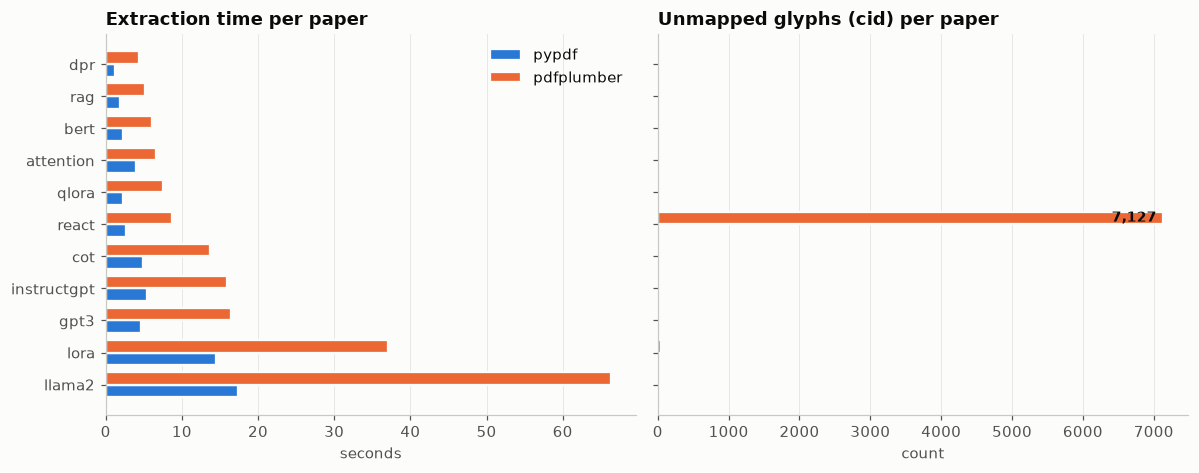

In [4]:
def grouped_barh(ax, table, columns, title, xlabel):
    # Horizontal grouped bars, one colour per column in fixed order, a surface-coloured gap between bars.
    rows = range(len(table))
    height = 0.8 / len(columns)
    for k, col in enumerate(columns):
        ax.barh([r + (k - (len(columns) - 1) / 2) * height for r in rows], table[col], height=height,
                color=SERIES[k], edgecolor=SURFACE, linewidth=1.5, label=col)
    ax.set_yticks(list(rows), table.index)
    ax.invert_yaxis()
    ax.grid(axis="y", visible=False)
    ax.set_title(title)
    ax.set_xlabel(xlabel)

wide = loader_cmp.pivot(index="paper_id", columns="loader")
order = wide[("seconds", "pdfplumber")].sort_values(ascending=False).index

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.4), sharey=True)
grouped_barh(ax1, wide["seconds"].loc[order], ["pypdf", "pdfplumber"], "Extraction time per paper", "seconds")
grouped_barh(ax2, wide["cid_glyphs"].loc[order], ["pypdf", "pdfplumber"], "Unmapped glyphs (cid) per paper", "count")
react_cid = wide.loc["react", ("cid_glyphs", "pdfplumber")]
ax2.annotate(f"{react_cid:,}", xy=(react_cid, list(order).index("react") + 0.2), xytext=(-4, 0),
             textcoords="offset points", ha="right", va="center", color=INK, fontsize=9, fontweight="bold")
ax1.legend(loc="upper right")
fig.tight_layout()

A sample makes the difference concrete: the ReAct page where `pdfplumber` produced the most unmapped glyphs, read by both loaders.

In [5]:
from rpab.loaders import discover_pdfs, identify, load_catalog, load_pdf, page_stats

catalog = load_catalog(CONFIG.paths.catalog)
react_pdf = next(p for p in discover_pdfs(CONFIG.paths.pdf_dir) if "2210.03629" in p.name)
react_meta = identify(react_pdf, catalog)
plumber_pages = load_pdf(react_pdf, react_meta, "pdfplumber")
worst = page_stats(plumber_pages, CONFIG.empty_page_chars).sort_values("cid_glyphs").iloc[-1]
page_no = int(worst["page"])
pypdf_page = load_pdf(react_pdf, react_meta, "pypdf")[page_no - 1]

print(f"ReAct page {page_no}: {int(worst['cid_glyphs'])} unmapped glyphs with pdfplumber\n")
print("pdfplumber:\n" + plumber_pages[page_no - 1].page_content[:320] + "\n")
print("pypdf:\n" + pypdf_page.page_content[:320])

ReAct page 2: 3112 unmapped glyphs with pdfplumber

pdfplumber:
PublishedasaconferencepaperatICLR2023
(cid:11)(cid:20)(cid:12)(cid:3)(cid:43)(cid:82)(cid:87)(cid:86)(cid:83)(cid:82)(cid:87)(cid:3)(cid:52)(cid:36) (cid:11)(cid:20)(cid:71)(cid:12)(cid:3)(cid:53)(cid:72)(cid:36)(cid:70)(cid:87)(cid:3)(cid:11)(cid:53)(cid:72)(cid:68)(cid:86)(cid:82)(cid:81)(cid:3)(cid:14)(cid:3)(cid:36

pypdf:
Published as a conference paper at ICLR 2023
$FW7KLQN>)LUVW,QHHGWRILQGDSHSSHUVKDNHUPRUH
OLNHO\WRDSSHDULQFDELQHWVFRXQWHUWRSV@
$FW*RWRFDELQHW
2EV2QWKHFDELQHW\RXVHHDYDVH
+HUHWKHDJHQWJRWRFDELQHWWKHQFDELQHWWKHQFRXQWHUWRSDQG
$FW*RW


**Observations.**

- `pypdf` is about 3× faster: 61 s against 188 s for all 411 pages. Llama 2 alone takes 66 s with `pdfplumber`.
- `pdfplumber` leaves 7,286 unmapped `(cid:NN)` glyphs, 7,127 of them in ReAct, where figure text uses an embedded font with a custom encoding. That text is lost for good.
- `pypdf` extracts the same ReAct text as letters shifted by 29 code points (sample above). It looks like noise, but it is recoverable in cleaning. None of the metrics above counted it, which is why the sample check matters.
- `pypdf` leaves 1,760 ligatures and 969 line-break hyphens; both are mechanical to fix.
- Two-column papers (BERT, DPR) come out in the right column order; checked on DPR page 2.

**Decision.** Use `PyPDFLoader` (`CONFIG.pdf_loader = "pypdf"`): faster, more text, and its defects can all be repaired, while `pdfplumber`'s cannot.

### 2.3 Cleaning

Rules in `rpab/cleaning.py`, applied in order to every page:

1. Replace ligatures with plain letters ("ﬁ" → "fi").
2. Decode shifted-font lines. Some ReAct figures embed a font whose character codes sit 29 below the real letters, so pypdf extracts "Think" as "7KLQN" and the space as the control character U+0003. A line where U+0003 outnumbers real spaces is shifted back; any other stray control character (a symbol glyph such as a check mark) is deleted.
3. Remove the arXiv side stamp (e.g. `arXiv:1706.03762v7 [cs.CL] 2 Aug 2023`).
4. Drop repeated header/footer lines: a line at a page's top or bottom edge whose shape (digits → `#`) appears at the edges of at least half the paper's pages. This removes page numbers and running heads.
5. Re-join words hyphenated across a line break ("ef-⏎ficient" → "efficient").
6. Normalise whitespace.

The raw text stays next to the cleaned text in `artifacts/pages.parquet`, so any cleaning decision can be audited later.

In [6]:
from rpab.cleaning import clean_documents

pages, page_log = clean_documents(raw_pages, CONFIG.repeated_line_share)
page_table = page_log.merge(page_stats(pages, CONFIG.empty_page_chars), on=["paper_id", "page"])
CONFIG.paths.artifacts_dir.mkdir(parents=True, exist_ok=True)
page_table.to_parquet(CONFIG.paths.pages, index=False)

rule_cols = ["ligatures_fixed", "shifted_lines_decoded", "control_chars_removed", "arxiv_stamps_removed",
             "edge_lines_removed", "hyphens_joined"]
cleaning = page_log.groupby("paper_id")[rule_cols].sum()
cleaning.loc["total"] = cleaning.sum()
cleaning

,ligatures_fixed,shifted_lines_decoded,control_chars_removed,arxiv_stamps_removed,edge_lines_removed,hyphens_joined
paper_id,,,,,,
attention,0,0,0,1,14,16
bert,157,0,0,1,0,332
cot,288,0,17,1,47,48
dpr,92,0,9,1,0,232
gpt3,444,0,0,1,74,23
instructgpt,352,0,0,1,77,43
llama2,0,0,1,1,76,66
lora,210,0,0,1,26,85
qlora,0,0,8,1,25,47


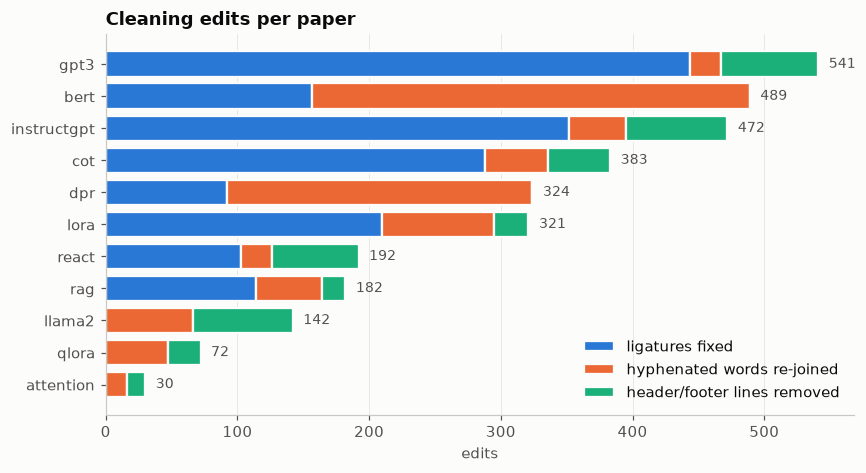

In [7]:
impact = page_log.groupby("paper_id")[["ligatures_fixed", "hyphens_joined", "edge_lines_removed"]].sum()
impact = impact.loc[impact.sum(axis=1).sort_values().index]
labels = {"ligatures_fixed": "ligatures fixed", "hyphens_joined": "hyphenated words re-joined",
          "edge_lines_removed": "header/footer lines removed"}

fig, ax = plt.subplots(figsize=(8, 4.4))
left = pd.Series(0, index=impact.index)
for k, col in enumerate(labels):
    ax.barh(impact.index, impact[col], left=left, color=SERIES[k], edgecolor=SURFACE, linewidth=1.5, label=labels[col])
    left = left + impact[col]
for y, total in enumerate(left):
    ax.text(total + 8, y, f"{int(total)}", va="center", color=INK_2, fontsize=9)
ax.grid(axis="y", visible=False)
ax.set_title("Cleaning edits per paper")
ax.set_xlabel("edits")
ax.legend(loc="lower right")
fig.tight_layout()

In [8]:
example = page_log[(page_log["paper_id"] == "dpr") & (page_log["page"] == 1)].iloc[0]
print("RAW:\n" + example["raw_text"][:430] + "\n")
print("CLEAN:\n" + example["clean_text"][:430])

RAW:
Dense Passage Retrieval for Open-Domain Question Answering
Vladimir Karpukhin∗, Barlas O˘guz∗, Sewon Min†, Patrick Lewis,
Ledell Wu, Sergey Edunov, Danqi Chen‡, Wen-tau Yih
Facebook AI †University of Washington ‡Princeton University
{vladk, barlaso, plewis, ledell, edunov, scottyih }@fb.com
sewon@cs.washington.edu
danqic@cs.princeton.edu
Abstract
Open-domain question answering relies on ef-
ﬁcient passage retrieval to select c

CLEAN:
Dense Passage Retrieval for Open-Domain Question Answering
Vladimir Karpukhin∗, Barlas O˘guz∗, Sewon Min†, Patrick Lewis,
Ledell Wu, Sergey Edunov, Danqi Chen‡, Wen-tau Yih
Facebook AI †University of Washington ‡Princeton University
{vladk, barlaso, plewis, ledell, edunov, scottyih }@fb.com
sewon@cs.washington.edu
danqic@cs.princeton.edu
Abstract
Open-domain question answering relies on efficient passage retrieval to select ca


**Observations.**

- 1,760 ligatures fixed and 965 hyphenated words re-joined. BERT and DPR, both two-column with narrow lines, account for most re-joins.
- 423 header/footer lines removed: page numbers in nine papers plus ReAct's running head. BERT and DPR have no repeated edge lines, so nothing was removed there.
- 198 ReAct figure lines decoded from the shifted font; the agent trajectories in its Figure 1 now read "Act 1: Think[First I need to find a pepper shaker…". 64 stray symbol characters removed in five papers.
- The first version of rule 2 shifted any line containing a control character and corrupted 30 normal lines in CoT, DPR, QLoRA and Llama 2, where a single check-mark glyph triggered it. Requiring U+0003 to outnumber real spaces fixed that; the affected lines were checked one by one.
- Known limits: a shifted line holding one word has no space to detect, so two ReAct figure labels stay garbled ("VRIWZDUH" is "software"). Footnote marks (∗ † ‡) and split accents ("O˘guz") remain. Neither matters for retrieval.

**Decision.** Keep all six rules. The raw text stays in `artifacts/pages.parquet` beside the cleaned text.

### 2.4 Quality report

In [9]:
from rpab.loaders import quality_report

stats = page_stats(pages, CONFIG.empty_page_chars)
print(f"Empty pages (OCR candidates): {int(stats['is_empty'].sum())} of {len(stats)}")
quality_report(stats)

Empty pages (OCR candidates): 0 of 411


,pages,empty_pages,total_chars,mean_chars_per_page,min_chars_per_page,ligatures,cid_glyphs,hyphen_breaks,non_ascii_share
paper_id,,,,,,,,,
llama2,77,0,260023,3376.922,156,0,0,0,0.003
gpt3,75,0,236810,3157.467,100,0,0,0,0.004
instructgpt,68,0,181751,2672.809,348,0,0,0,0.003
cot,43,0,135506,3151.302,634,0,0,0,0.003
react,33,0,108365,3283.788,597,0,0,0,0.002
qlora,26,0,87637,3370.654,383,0,0,0,0.002
lora,26,0,82360,3167.692,1771,0,0,0,0.006
rag,19,0,68962,3629.579,1129,0,0,0,0.003
bert,16,0,63502,3968.875,2324,0,0,0,0.002


**Observations.** 0 of 411 pages are empty, and no ligatures, unmapped glyphs or line-break hyphens remain after cleaning, so every PDF has a usable text layer. The shortest pages (100 to 400 characters) are figure or table pages, not extraction failures.

**Decision.** OCR is not needed for this corpus. The empty-page count stays in the ingestion report, so a scanned PDF added later would be flagged.

### 2.5 Exploring the corpus

Corpus: 357,295 tokens


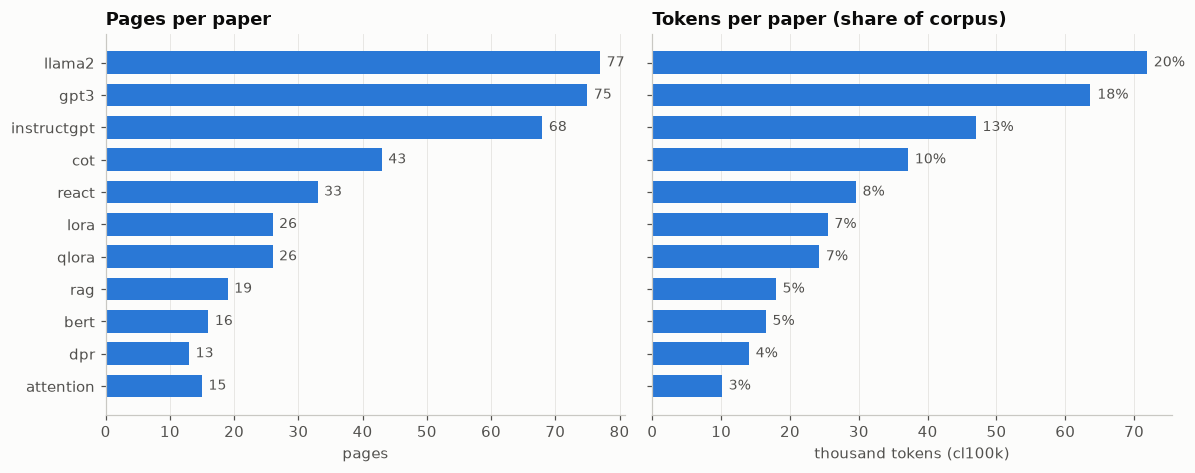

In [10]:
from rpab.eda import back_matter_split, count_tokens

page_table["tokens"] = count_tokens(page_table["clean_text"])
per_paper = page_table.groupby("paper_id").agg(pages=("page", "count"), tokens=("tokens", "sum"))
per_paper["token_share"] = per_paper["tokens"] / per_paper["tokens"].sum()
per_paper = per_paper.sort_values("tokens")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.4), sharey=True)
ax1.barh(per_paper.index, per_paper["pages"], color=SERIES[0], height=0.7)
for y, v in enumerate(per_paper["pages"]):
    ax1.text(v + 1, y, str(v), va="center", color=INK_2, fontsize=9)
ax1.set_title("Pages per paper")
ax1.set_xlabel("pages")
ax2.barh(per_paper.index, per_paper["tokens"] / 1000, color=SERIES[0], height=0.7)
for y, (v, s) in enumerate(zip(per_paper["tokens"], per_paper["token_share"])):
    ax2.text(v / 1000 + 1, y, f"{s:.0%}", va="center", color=INK_2, fontsize=9)
ax2.set_title("Tokens per paper (share of corpus)")
ax2.set_xlabel("thousand tokens (cl100k)")
for ax in (ax1, ax2):
    ax.grid(axis="y", visible=False)
fig.tight_layout()
print(f"Corpus: {per_paper['tokens'].sum():,} tokens")

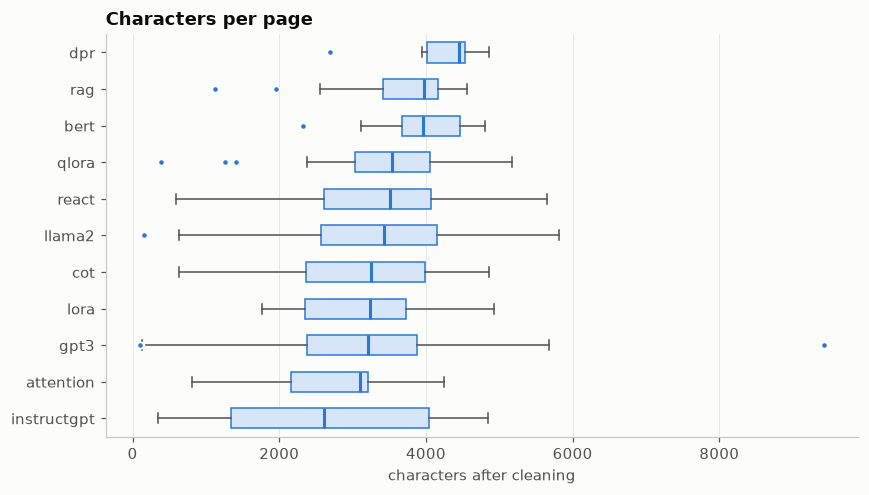

In [11]:
order = page_table.groupby("paper_id")["n_chars"].median().sort_values().index
fig, ax = plt.subplots(figsize=(8, 4.6))
ax.boxplot([page_table.loc[page_table["paper_id"] == p, "n_chars"] for p in order], orientation="horizontal",
           tick_labels=list(order), widths=0.55, patch_artist=True,
           boxprops=dict(facecolor="#d6e6f8", edgecolor=SERIES[0]), medianprops=dict(color=SERIES[0], linewidth=2),
           whiskerprops=dict(color=INK_2), capprops=dict(color=INK_2),
           flierprops=dict(marker="o", markersize=4, markerfacecolor=SERIES[0], markeredgecolor=SURFACE))
ax.grid(axis="y", visible=False)
ax.set_title("Characters per page")
ax.set_xlabel("characters after cleaning")
fig.tight_layout()

,references_page,body_pages,back_matter_pages,total_pages
paper_id,,,,
dpr,9,8,5,13
attention,10,9,6,15
bert,10,9,7,16
rag,10,9,10,19
qlora,17,16,10,26
lora,13,12,14,26
react,10,9,24,33
cot,10,9,34,43
instructgpt,21,20,48,68


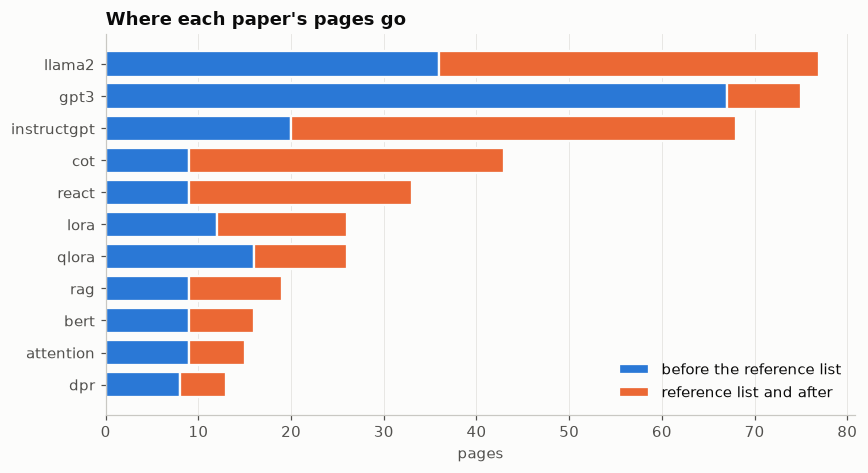

In [12]:
split = back_matter_split(page_table).sort_values("total_pages")
fig, ax = plt.subplots(figsize=(8, 4.4))
ax.barh(split.index, split["body_pages"], color=SERIES[0], edgecolor=SURFACE, linewidth=1.5, label="before the reference list")
ax.barh(split.index, split["back_matter_pages"], left=split["body_pages"], color=SERIES[1], edgecolor=SURFACE,
        linewidth=1.5, label="reference list and after")
ax.grid(axis="y", visible=False)
ax.set_title("Where each paper's pages go")
ax.set_xlabel("pages")
ax.legend(loc="lower right")
fig.tight_layout()
split

**Observations.**

- The corpus is 411 pages and about 361k tokens. Three long papers hold just over half of it: Llama 2 (20%), GPT-3 (18%) and InstructGPT (13%). Attention Is All You Need is only 3%.
- Pages hold a median of 3,404 characters (middle half: 2,409 to 4,079). An 800-character chunk is about a quarter of a page, so most pages yield 4 to 5 chunks.
- In six papers more than half the pages come after the reference list starts: CoT 34 of 43, InstructGPT 48 of 68, ReAct 24 of 33, Llama 2 41 of 77, LoRA 14 of 26, RAG 10 of 19. GPT-3 is the exception because its appendices come before its references.

**Implications for the next steps.**

- Long papers will contribute the most chunks and so get more chances to appear in the top results. The evaluation questions must cover the short papers too, and retrieval results will be checked per paper.
- Appendices hold real content (extra experiments, prompts, model details) and stay in the index. Reference lists are mostly author names and venues; whether removing them improves retrieval will be tested as a chunking variant in section 3.
- Chunks must not cross page boundaries, so chunk size has to sit well below the typical page length. The 500, 800 and 1,200-character variants all do.

## 3. Chunking experiments

**Intent.** Pick the chunking that puts the passage holding the answer in the top 3. Every variant splits one page at a time, so a chunk never crosses a page boundary and its page number is exact; chunks under 100 characters (stray figure labels) are dropped. Each chunk gets a deterministic id, `{paper_id}_p{page:03d}_c{index:03d}`, and a SHA-256 of its text that keys the embedding cache.

**Method.** Each grid point is embedded with one model (`bge-m3`), stored in its own Chroma collection and scored with dense top-10 retrieval on the **dev** questions only. A retrieved chunk is a hit when its page is a gold page *of its own paper*. Held-out questions are not touched until final reporting.

> **Re-scored after the gold-page audit (section 6.1).** These experiments first ran against gold labels that listed only one main page per fact. Section 6 found that the papers repeat key facts in their appendices, so the labels were audited and every run here was re-scored from its saved retrieval results. All numbers below use the audited labels, and the decisions say where the audit changed them.

### 3.1 Evaluation set

29 questions in `data/eval/eval_questions.json`: 24 answerable, spread over all 11 papers and five question types, and 5 out of scope. 14 questions (48%) are `held_out`, and every paper has at least one held-out question.

- **Gold pages are per paper**, e.g. `{"lora": [2, 4], "qlora": [1, 2, 3, 4, 5]}`, so a comparison question is only hit by the right page *of the right paper*. Page numbers are positions in the ingested PDF files, the same numbering the chunks carry.
- **A page is gold** when, read alone, it states what the reference answer relies on: the whole answer, or one named part of a two-part question. For list questions (the three InstructGPT steps, the three ReAct actions) the page must state the set. Passing mentions (a results table that only names the method, a related-work line) are not gold. Candidates were found by searching the page text for each question's key facts, never from retrieval output, and each candidate was read (section 6.1).
- **Out-of-scope questions are hard negatives.** Two ask about nearby work the corpus does not contain (GPT-4's size, Mamba), one about Stable Diffusion, and two ask for details the corpus papers never state: GPT-3's training cost in dollars and BERT's energy use. Each was checked against the page text to confirm the answer is absent; the BERT one is a trap, since Llama 2 does report carbon emissions. Retrieval metrics skip these questions because they have no gold passage; they are scored as *should refuse* by the weak-context threshold (section 6.3) and the answer evaluation (section 8).
- The held-out questions for BERT, GPT-3, InstructGPT and QLoRA (q028–q031) were written after the chunking and embedding experiments, so they never influenced them. No dev question was moved to held-out, because dev questions had already shaped those choices.
- The reference answers and the out-of-scope set were reviewed by the author.

split     answerable
dev       False          3
          True          12
held_out  False          2
          True          12 

split          dev  held_out
type                        
comparison       1         1
conceptual       4         2
factual          0         3
method_detail    4         2
numeric          3         4


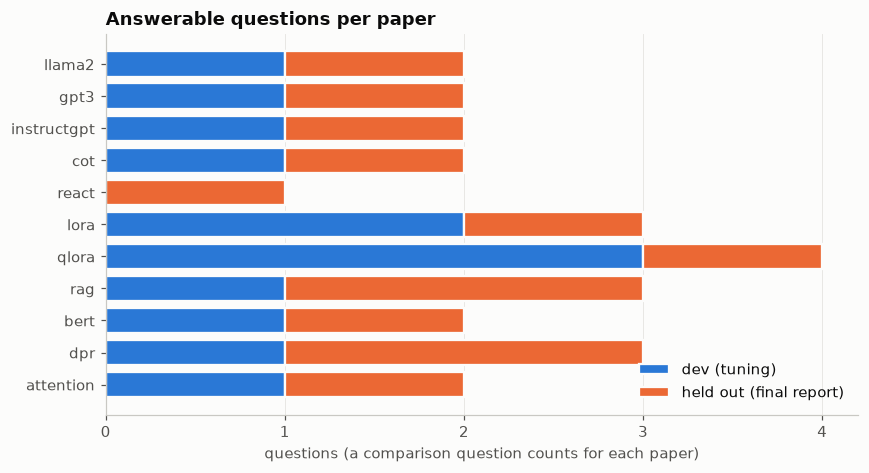

In [13]:
import json

eval_set = json.loads(CONFIG.paths.eval_questions.read_text(encoding="utf-8"))
eval_df = pd.DataFrame(eval_set)
print(eval_df.groupby(["split", "answerable"]).size().rename("questions").to_string(), "\n")
print(eval_df[eval_df["answerable"]].groupby(["type", "split"]).size().unstack(fill_value=0).to_string())

coverage = (eval_df[eval_df["answerable"]].explode("gold_papers")
            .groupby(["gold_papers", "split"]).size().unstack(fill_value=0)
            .reindex(per_paper.index, fill_value=0))
fig, ax = plt.subplots(figsize=(8, 4.4))
ax.barh(coverage.index, coverage["dev"], color=SERIES[0], edgecolor=SURFACE, linewidth=1.5, label="dev (tuning)")
ax.barh(coverage.index, coverage["held_out"], left=coverage["dev"], color=SERIES[1], edgecolor=SURFACE,
        linewidth=1.5, label="held out (final report)")
ax.grid(axis="y", visible=False)
ax.set_title("Answerable questions per paper")
ax.set_xlabel("questions (a comparison question counts for each paper)")
ax.set_xticks(range(0, int(coverage.sum(axis=1).max()) + 1))
ax.legend(loc="lower right")
fig.tight_layout()

### 3.2 Chunking grid

The grid from the technical plan, plus two capped semantic variants: the semantic chunker has no size limit, so those re-split any chunk longer than 1,200 characters. Sizes are characters for `recursive` and tokens (cl100k) for `fixed`.

In [14]:
from rpab.chunking import ChunkSpec
from rpab.embeddings import load_embedder
from rpab.evaluation import load_eval_set, read_experiments
from rpab.experiments import CHUNK_GRID, run_chunking_grid
from rpab.vectorstore import get_client

dev = load_eval_set(CONFIG.paths.eval_questions, split="dev")
client = get_client(CONFIG.paths.chroma_dir)
bge = load_embedder("open", CONFIG)
NOREF = [ChunkSpec("recursive", 1200, 150, drop_references=True), ChunkSpec("fixed", 512, 0, drop_references=True)]
chunk_results_path = CONFIG.paths.artifacts_dir / "chunking_per_question.parquet"

if RUN_EXPERIMENTS or not chunk_results_path.exists():
    chunk_results = run_chunking_grid(CHUNK_GRID + NOREF, page_table, bge, client, dev, CONFIG)
    chunk_results.to_parquet(chunk_results_path, index=False)
else:
    chunk_results = pd.read_parquet(chunk_results_path)

grid = read_experiments(CONFIG.paths.experiments, "chunking").set_index("chunking")
grid_cols = ["run_id", "hit_at_1", "hit_at_3", "hit_at_5", "mrr", "precision_at_3", "num_chunks",
             "mean_chunk_chars", "embed_seconds", "index_size_mb", "notes"]
grid.loc[~grid.index.str.endswith("_noref"), grid_cols].sort_values(["hit_at_3", "mrr"], ascending=False)

C:\Users\Asus\Desktop\Research Paper Answer Bot\backend\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


W1025 00:03:46.576000 27068 .venv\Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

Loading weights:   1%|▏         | 5/391 [00:02<02:52,  2.23it/s]

Loading weights: 100%|██████████| 391/391 [00:02<00:00, 172.48it/s]

,run_id,hit_at_1,hit_at_3,hit_at_5,mrr,precision_at_3,num_chunks,mean_chunk_chars,embed_seconds,index_size_mb,notes
chunking,,,,,,,,,,,
fixed_512_50,exp_010,0.917,1.000,1.000,0.958,0.611,943,1505.0,13.7,3.9,chunking took 0.7 s
recursive_1200_150,exp_005,0.917,1.000,1.000,0.944,0.639,1418,1005.5,17.8,5.8,chunking took 0.4 s
recursive_800_200,exp_004,0.833,1.000,1.000,0.917,0.667,2277,705.9,18.4,9.3,chunking took 0.4 s
fixed_512_0,exp_009,0.833,1.000,1.000,0.917,0.556,891,1479.8,15.8,3.6,chunking took 0.8 s
semantic_p90,exp_011,0.833,1.000,1.000,0.917,0.667,1576,827.8,15.4,6.5,chunking took 89.0 s
semantic_p95,exp_012,0.833,1.000,1.000,0.917,0.667,1131,1159.3,20.2,4.6,chunking took 88.8 s
recursive_1200_200,exp_006,0.750,1.000,1.000,0.875,0.639,1456,1017.6,15.7,6.0,chunking took 0.4 s
fixed_256_0,exp_007,0.750,1.000,1.000,0.847,0.528,1562,843.1,12.5,6.4,chunking took 0.3 s
semantic_p95_max1200_150,exp_014,0.917,0.917,0.917,0.929,0.611,1740,785.8,16.9,7.1,chunking took 89.2 s


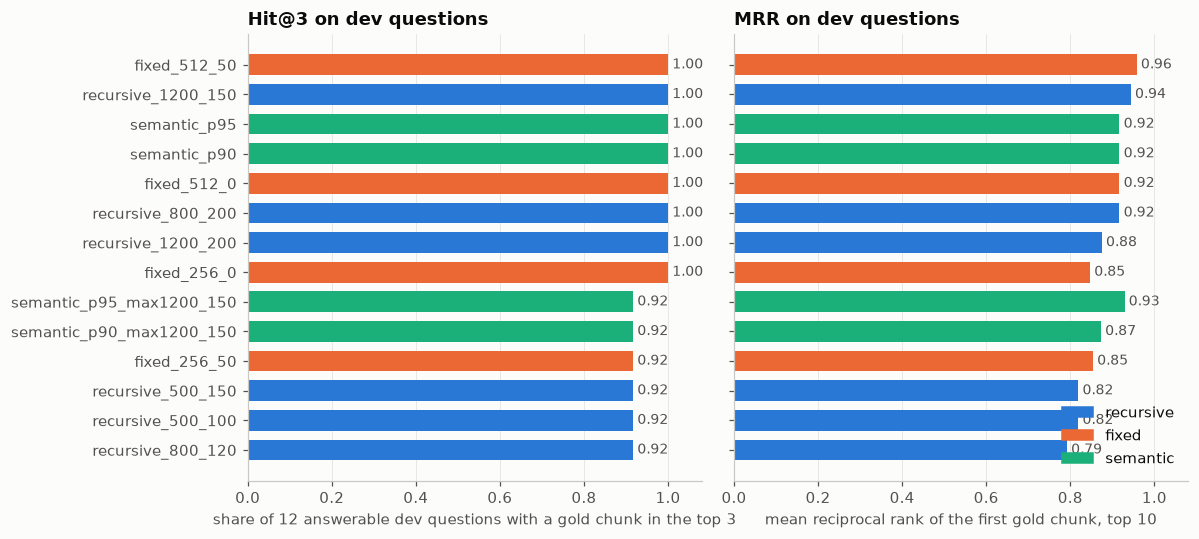

In [15]:
main_grid = grid[~grid.index.str.endswith("_noref")].sort_values(["hit_at_3", "mrr"])
colours = main_grid["chunking_strategy"].map({"recursive": SERIES[0], "fixed": SERIES[1], "semantic": SERIES[2]})
n_dev = sum(q["answerable"] for q in dev)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 5), sharey=True)
for ax, col, title in [(ax1, "hit_at_3", "Hit@3 on dev questions"), (ax2, "mrr", "MRR on dev questions")]:
    ax.barh(main_grid.index, main_grid[col], color=colours, height=0.7)
    for y, v in enumerate(main_grid[col]):
        ax.text(v + 0.01, y, f"{v:.2f}", va="center", color=INK_2, fontsize=9)
    ax.set_xlim(0, 1.08)
    ax.grid(axis="y", visible=False)
    ax.set_title(title)
ax1.set_xlabel(f"share of {n_dev} answerable dev questions with a gold chunk in the top 3")
ax2.set_xlabel("mean reciprocal rank of the first gold chunk, top 10")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in SERIES]
ax2.legend(handles, ["recursive", "fixed", "semantic"], loc="lower right")
fig.tight_layout()

With 12 answerable dev questions, one question moves hit@3 by 0.083. The rank of the first gold chunk per question shows where the configurations really differ (`<NA>` = not in the top 10):

In [16]:
ranks = chunk_results.assign(rank=(1 / chunk_results["reciprocal_rank"]).where(chunk_results["reciprocal_rank"] > 0))
ranks.pivot(index="question_id", columns="chunking", values="rank")[main_grid.index[::-1]].T.astype("Int64")

question_id,q001,q003,q004,q006,q008,q009,q011,q013,q015,q016,q018,q019
chunking,,,,,,,,,,,,
fixed_512_50,1,1,1,1,1,1,1,1,2,1,1,1
recursive_1200_150,1,1,1,1,1,1,3,1,1,1,1,1
semantic_p95,1,1,1,1,1,2,2,1,1,1,1,1
semantic_p90,1,1,1,1,1,2,2,1,1,1,1,1
fixed_512_0,1,1,1,1,1,1,1,1,2,2,1,1
recursive_800_200,1,1,1,1,2,2,1,1,1,1,1,1
recursive_1200_200,1,2,1,1,1,1,2,1,1,2,1,1
fixed_256_0,1,1,1,1,1,3,3,1,1,1,2,1
semantic_p95_max1200_150,1,1,1,1,1,7,1,1,1,1,1,1


recursive_1200_150: 0 chunks over 1,024 tokens, longest 912
fixed_512_0: 0 chunks over 1,024 tokens, longest 513
semantic_p95: 14 chunks over 1,024 tokens, longest 6973


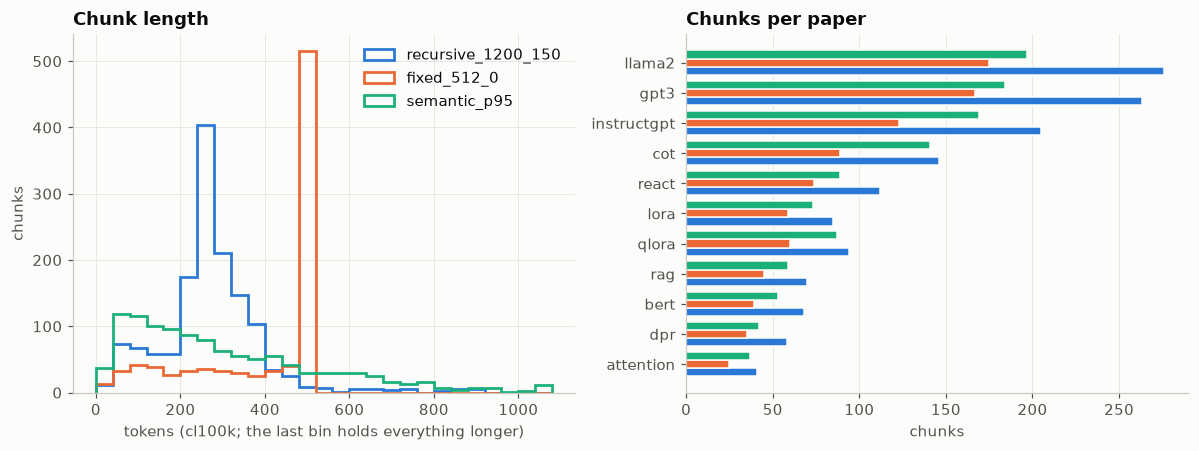

In [17]:
grid_chunks = {slug: pd.read_parquet(CONFIG.paths.chunk_grid_dir / f"{slug}.parquet")
               for slug in ["recursive_1200_150", "fixed_512_0", "semantic_p95"]}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2))
bins = range(0, 1100, 40)
for k, (slug, chunks) in enumerate(grid_chunks.items()):
    ax1.hist(chunks["token_count"].clip(upper=1080), bins=bins, histtype="step", linewidth=1.8, color=SERIES[k], label=slug)
ax1.set_title("Chunk length")
ax1.set_xlabel("tokens (cl100k; the last bin holds everything longer)")
ax1.set_ylabel("chunks")
ax1.legend(loc="upper right")

counts = pd.DataFrame({slug: c.groupby("paper_id").size() for slug, c in grid_chunks.items()}).loc[per_paper.index]
rows = range(len(counts))
for k, slug in enumerate(counts.columns):
    ax2.barh([r + (k - 1) * 0.27 for r in rows], counts[slug], height=0.27, color=SERIES[k], edgecolor=SURFACE, linewidth=1)
ax2.set_yticks(list(rows), counts.index)
ax2.grid(axis="y", visible=False)
ax2.set_title("Chunks per paper")
ax2.set_xlabel("chunks")
fig.tight_layout()
for slug, c in grid_chunks.items():
    print(f"{slug}: {(c['token_count'] > 1024).sum()} chunks over 1,024 tokens, longest {c['token_count'].max()}")

### 3.3 Dropping reference lists

Section 2 found that reference lists fill many pages. A chunk is treated as bibliography when it has at least 4 years *and* at least 1 venue word (Proceedings, arXiv, Conference, URL...) per 1,000 characters; heavily cited body text has years but almost never venue words. The two best bounded configurations are re-run without those chunks.

In [18]:
from rpab.chunking import looks_like_references

noref = grid.loc[[s.slug for s in NOREF] + [s.slug.removesuffix("_noref") for s in NOREF], grid_cols[:8]]
display(noref)
full = grid_chunks["fixed_512_0"]
flagged = full[full["text"].map(looks_like_references)]
print(f"fixed_512_0: {len(flagged)} of {len(full)} chunks dropped as bibliography; per paper:",
      flagged.groupby("paper_id").size().to_dict())
print("\nSample dropped chunk:\n" + flagged.sample(1, random_state=CONFIG.seed)["text"].iloc[0][:300])

,run_id,hit_at_1,hit_at_3,hit_at_5,mrr,precision_at_3,num_chunks,mean_chunk_chars
chunking,,,,,,,,
recursive_1200_150_noref,exp_015,0.917,1.0,1.0,0.944,0.639,1242,1005.8
fixed_512_0_noref,exp_016,0.833,1.0,1.0,0.917,0.528,766,1501.7
recursive_1200_150,exp_005,0.917,1.0,1.0,0.944,0.639,1418,1005.5
fixed_512_0,exp_009,0.833,1.0,1.0,0.917,0.556,891,1479.8


fixed_512_0: 125 of 891 chunks dropped as bibliography; per paper: {'attention': 4, 'bert': 7, 'cot': 12, 'dpr': 5, 'gpt3': 22, 'instructgpt': 14, 'llama2': 19, 'lora': 11, 'qlora': 13, 'rag': 13, 'react': 5}

Sample dropped chunk:
QA: A
question answering challenge targeting commonsense knowledge. NAACL.
Alon Talmor, Oyvind Tafjord, Peter Clark, Yoav Goldberg, and Jonathan Berant. 2020. Leap-ofthought: Teaching pre-trained models to systematically reason over implicit knowledge. NeurIPS.
Alon Talmor, Ori Yoran, Ronan Le Bras,


**Observations** (audited labels).

- Hit@3 no longer separates the configurations: eight of the fourteen reach 1.000 and the rest 0.917, so every configuration finds a gold page in the top 3 for at least 11 of the 12 dev questions. MRR and hit@1 now carry the differences: `fixed_512_50` (MRR 0.958, hit@1 0.917) and `recursive_1200_150` (0.944, 0.917) lead, and `fixed_512_0` follows at 0.917 / 0.833.
- Larger chunks do slightly better: the five configurations averaging 1,000+ characters average MRR 0.922 and hit@1 0.850, against 0.863 and 0.787 for the nine smaller ones. Part of this is the metric itself: gold labels are pages, so a chunk covering more of a page is more likely to count as a hit.
- The clearest failure is q009 (how LoRA initialises A and B): the 500-character and `recursive_800_120` chunkings miss it entirely in the top 10, probably because the sentence about initialisation lands in a small chunk without enough surrounding LoRA context to match the question.
- Overlap has no consistent effect: `fixed_512_50` beats `fixed_512_0` by one rank on one question (q016), while `recursive_1200_200` trails `recursive_1200_150`.
- The semantic chunker is among the best on hit@3 but leaves 14 chunks over 1,024 tokens (the longest, 6,973 tokens, is a table page with no breakpoint). bge-m3 truncates those at its 1,024-token cap. It also takes about 89 s per run because it embeds every sentence. Capping its chunks at 1,200 characters lowers hit@3 to 0.917, so its advantage came from large chunks, not from where it breaks.
- Dropping bibliography chunks removes 125 of 891 chunks (14%) from `fixed_512_0` and 176 from `recursive_1200_150`, and changes no metric. The sample confirms the filter catches reference entries.
- Embedding each grid point with bge-m3 takes 12–21 s on the RTX 4060; vector storage ranges from 3.6 MB (fixed 512) to 15.7 MB (recursive 500).

**Decision.** Keep **`fixed_512_0_noref`**: 512-token chunks, no overlap, bibliography chunks dropped (`CONFIG.chunking_strategy = "fixed"`, `chunk_size = 512`, `chunk_overlap = 0`, `drop_references = True`). It was chosen on the original labels for its tied-best hit@3 and bounded size, and it is still tied for the best hit@3 after the audit. On MRR it now trails `fixed_512_50` and `recursive_1200_150` by about one question ranked second instead of first. Section 6 shows that reranking puts a gold page first for every dev question on this chunking, so the gap does not justify rebuilding every index. Its chunks never exceed 513 tokens, so nothing is truncated and three passages (about 1,200 tokens) fit easily in the 8k context. Known risk: a fixed token window can cut a sentence in two; `fixed_512_50` is the alternative if the failure analysis in section 8 finds answers split across chunks.

## 4. Embedding model comparison

**Intent.** Compare one open-source and one commercial embedding model on the chosen chunking, with the same chunks and the same dev questions, and pick the one the bot uses.

| | `BAAI/bge-m3` | `gemini-embedding-001` |
|---|---|---|
| Type | open-source, runs locally on the GPU (float16) | commercial API, free tier |
| Dimensions | 1,024 | 3,072 |
| Query vs document | same encoder, no prefix | task types `RETRIEVAL_QUERY` / `RETRIEVAL_DOCUMENT` |

Gemini requests carry 50 texts, are paced to stay under the per-minute token limit and retry with backoff on rate-limit errors. Every document vector is cached by text hash, so nothing is embedded twice. The local model is timed by re-embedding from scratch; Gemini's time is its first (uncached) run.

In [19]:
from rpab.embeddings import GeminiEmbedder, GeminiQuotaExhausted
from rpab.experiments import run_embedding_comparison

chunks = pd.read_parquet(CONFIG.paths.chunk_grid_dir / f"{CONFIG.chunk_spec.slug}.parquet")
emb_results_path = CONFIG.paths.artifacts_dir / "embedding_per_question.parquet"
# The notebook runs without a Gemini key: saved results are used and live Gemini cells are skipped
gemini = load_embedder("commercial", CONFIG) if CONFIG.google_api_key else None
embedders = {"bge-m3": bge, **({"gemini": gemini} if gemini else {})}

if RUN_EXPERIMENTS or not emb_results_path.exists():
    emb_results = run_embedding_comparison(CONFIG.chunk_spec, chunks, list(embedders.values()), client, dev, CONFIG)
    emb_results.to_parquet(emb_results_path, index=False)
else:
    emb_results = pd.read_parquet(emb_results_path)

emb_table = read_experiments(CONFIG.paths.experiments, "embedding").set_index("embedding_model")
emb_table["dim"] = [bge.dim if "bge" in m else GeminiEmbedder.dim for m in emb_table.index]
emb_table[["run_id", "chunking", "hit_at_1", "hit_at_3", "hit_at_5", "mrr", "precision_at_3", "latency_ms",
           "embed_seconds", "dim", "index_size_mb", "cost_usd"]]

,run_id,chunking,hit_at_1,hit_at_3,hit_at_5,mrr,precision_at_3,latency_ms,embed_seconds,dim,index_size_mb,cost_usd
embedding_model,,,,,,,,,,,,
BAAI/bge-m3,exp_017,fixed_512_0_noref,0.833,1.0,1.0,0.917,0.556,27.4,10.9,1024,3.1,0.0000
models/gemini-embedding-001,exp_018,fixed_512_0_noref,0.833,1.0,1.0,0.889,0.639,474.0,882.1,3072,9.4,0.0457


In [20]:
emb_ranks = emb_results.assign(rank=(1 / emb_results["reciprocal_rank"]).where(emb_results["reciprocal_rank"] > 0))
emb_ranks.pivot(index="question_id", columns="embedding_model", values="rank").astype("Int64")

embedding_model,BAAI/bge-m3,models/gemini-embedding-001
question_id,,
q001,1,1
q003,1,1
q004,1,1
q006,1,1
q008,1,1
q009,1,1
q011,1,3
q013,1,1
q015,2,3


### 4.1 Manual sanity queries

Five questions that are **not** in the eval set, answered by both collections. The top 3 chunks are read by hand to judge whether they are on topic, and whether `paper_title` and `page` came through intact.

In [21]:
from rpab.vectorstore import collection_name, dense_search

SANITY = [
    "What optimizer and learning rate schedule were used to train the Transformer?",
    "Which corpora was BERT pre-trained on?",
    "Which weight matrices of the Transformer does LoRA adapt in its experiments?",
    "What is a paged optimizer?",
    "How does ReAct compare with chain-of-thought prompting on HotpotQA?",
]
sanity_path = CONFIG.paths.artifacts_dir / "sanity_queries.parquet"
saved = pd.read_parquet(sanity_path) if sanity_path.exists() else pd.DataFrame()
rows = []
for name, embedder in embedders.items():
    if not RUN_EXPERIMENTS and not saved.empty and name in set(saved["model"]):
        continue  # reuse the saved results for this model
    collection = client.get_collection(collection_name(embedder.slug, CONFIG.chunk_spec.slug))
    try:
        for q_num, question in enumerate(SANITY, start=1):
            for rank, hit in enumerate(dense_search(collection, embedder, question, 3), start=1):
                rows.append({"query": q_num, "model": name, "rank": rank, "paper_title": hit["paper_title"][:38],
                             "page": hit["page"], "score": hit["score"], "snippet": hit["text"][:110].replace("\n", " ")})
    except GeminiQuotaExhausted as exc:
        rows = [r for r in rows if r["model"] != name]
        print(f"{name} skipped: {exc}")
fresh = pd.DataFrame(rows)
sanity = pd.concat([saved[~saved["model"].isin(set(fresh.get("model", [])))] if not saved.empty else saved, fresh])
if not fresh.empty:
    sanity.to_parquet(sanity_path, index=False)
for q_num, question in enumerate(SANITY, start=1):
    print(f"Q{q_num}. {question}")
sanity.sort_values(["query", "model", "rank"]).set_index(["query", "model", "rank"])

Q1. What optimizer and learning rate schedule were used to train the Transformer?
Q2. Which corpora was BERT pre-trained on?
Q3. Which weight matrices of the Transformer does LoRA adapt in its experiments?
Q4. What is a paged optimizer?
Q5. How does ReAct compare with chain-of-thought prompting on HotpotQA?


paper_title  page   score  \
query model  rank                                                         
1     bge-m3 1                  Attention Is All You Need     8  0.6124   
             2                  Attention Is All You Need     7  0.6087   
             3     LoRA: Low-Rank Adaptation of Large Lan     9  0.5853   
      gemini 1                  Attention Is All You Need     7  0.7826   
             2     Training language models to follow ins    40  0.7369   
             3     Training language models to follow ins    41  0.7335   
2     bge-m3 1     BERT: Pre-training of Deep Bidirection     3  0.5630   
             2     BERT: Pre-training of Deep Bidirection     1  0.5302   
             3     BERT: Pre-training of Deep Bidirection     5  0.5117   
      gemini 1     BERT: Pre-training of Deep Bidirection     5  0.7830   
             2     BERT: Pre-training of Deep Bidirection    14  0.7510   
             3     BERT: Pre-training of Deep Bidirection     3  0.7496   
3     bge-m3 1     LoRA: Low-Rank Adaptation of Large Lan     5  0.7000   
             2     LoRA: Low-Rank Adaptation of Large Lan     4  0.6318   
             3     LoRA: Low-Rank Adaptation of Large Lan     1  0.6314   
      gemini 1     LoRA: Low-Rank Adaptation of Large Lan     5  0.8012   
             2     LoRA: Low-Rank Adaptation of Large Lan    10  0.7892   
             3     LoRA: Low-Rank Adaptation of Large Lan     2  0.7873   
4     bge-m3 1     QLoRA: Efficient Finetuning of Quantiz     5  0.4901   
             2     LoRA: Low-Rank Adaptation of Large Lan     9  0.4786   
             3     Retrieval-Augmented Generation for Kno     4  0.4736   
      gemini 1     QLoRA: Efficient Finetuning of Quantiz     5  0.7197   
             2     QLoRA: Efficient Finetuning of Quantiz     3  0.6804   
             3     QLoRA: Efficient Finetuning of Quantiz     5  0.6689   
5     bge-m3 1     ReAct: Synergizing Reasoning and Actin     3  0.7171   
             2     ReAct: Synergizing Reasoning and Actin     2  0.7098   
             3     ReAct: Synergizing Reasoning and Actin     5  0.7005   
      gemini 1     ReAct: Synergizing Reasoning and Actin     5  0.8163   
             2     ReAct: Synergizing Reasoning and Actin     5  0.8141   
             3     ReAct: Synergizing Reasoning and Actin    14  0.8103   

                                                                                                     snippet  
query model  rank                                                                                             
1     bge-m3 1     , establishing a new state-of-the-art BLEU score of 28.4. The configuration of this mo...  
             2     machine with 8 NVIDIA P100 GPUs. For our base models using the hyperparameters describ...  
             3     tasks. Note that the low-rank structure not only lowers the hardware barrier to entry ...  
      gemini 1     machine with 8 NVIDIA P100 GPUs. For our base models using the hyperparameters describ...  
             2     . For 175B, we use a LR of 5.03e-6 and a batch size of 8. To select learning rates, we...  
             3     to 10% of its initial value by the end of training), and a batch size of 64. Training ...  
2     bge-m3 1     BERT BERT E[CLS] E1 E[SEP]... EN E1’ ... EM’ C T1 T[SEP]... TN T1’ ... TM’ [CLS] Tok 1...  
             2     BERT: Pre-training of Deep Bidirectional Transformers for Language Understanding Jacob...  
             3     [CLS] he likes play ##ing [SEP]my dog is cute [SEP]Input E[CLS] Ehe Elikes Eplay E##in...  
      gemini 1     [CLS] he likes play ##ing [SEP]my dog is cute [SEP]Input E[CLS] Ehe Elikes Eplay E##in...  
             2     • Learning rate (Adam): 5e-5, 3e-5, 2e-5 • Number of epochs: 2, 3, 4 We also observed ...  
             3     BERT BERT E[CLS] E1 E[SEP]... EN E1’ ... EM’ C T1 T[SEP]... TN T1’ ... TM’ [CLS] Tok 1...  
3     bge-m3 1     guarantees that we do not introduce any additional latency during infere

**Observations** (audited labels).

- Both models put a gold page in the top 3 for all 12 dev questions, and both reach hit@1 0.833. bge-m3 has the higher MRR (0.917 vs 0.889); Gemini the higher precision@3 (0.639 vs 0.556).
- Per question, the two differ on q011 (bge-m3 rank 1, Gemini 3), q015 (2 vs 3) and q016 (2 vs 1).
- Before the audit Gemini looked clearly better (hit@3 1.000 vs 0.917, MRR 0.833 vs 0.736). Most of that gap came from pages the original labels did not list: bge-m3 found correct appendix pages that were scored as misses.
- Sanity queries (not part of the audit): both models put the page that answers the question in the top 3 for all five. Gemini ranks it first in all five; bge-m3 in two (Q3, Q4). bge-m3's misses pull in off-topic chunks (a LoRA page for the Transformer optimizer, a RAG page for paged optimizers). Titles and pages came through intact in every result.
- Cost and speed: bge-m3 embeds the 766 chunks in 11 s locally, for free. Gemini took 882 s, almost all of it waiting, because requests are paced to the free tier's per-minute token limit. About 288k tokens were sent: free on the free tier, about $0.05 at the paid list price. A Gemini query takes 0.5–1 s (a network round trip) against tens of milliseconds locally. Its 3,072-dim vectors take 3× the space (9.4 vs 3.1 MB).
- Gemini adds dependencies: an internet connection, an API key, a daily quota, and query text sent to Google.

**Decision.** First decision (original labels): Gemini, with bge-m3 as the offline fallback. **Revised after the audit: `BAAI/bge-m3`** (`CONFIG.embedding_choice = "open"`). On dense retrieval the two models are now level, and section 6 shows that after reranking they return the same top passages for every dev question. That leaves latency (about 0.55 s vs 0.9–1.3 s per question with reranking, depending on the network), privacy and the API dependency, and all three favour the local model. Gemini stays indexed and selectable (`RPAB_EMBEDDING=commercial`), and section 6.5 reports it on the held-out questions alongside the final system.

## 5. Vector database build

**Intent.** Persist the chosen chunks and their vectors so the bot can start without re-embedding, and prove the index is complete and consistent.

- `artifacts/chunks.parquet` is the canonical chunk table; Chroma and (in section 6) BM25 are rebuilt from it.
- One collection per embedding model × chunking, named `papers__{embedding}__{chunking}`, cosine distance, with the model, dimension, chunking and creation time stored as collection metadata. A query is refused if its embedder differs from the one recorded on the collection.
- `scripts/ingest.py chunk index` rebuilds both from the saved pages.

In [22]:
from rpab.vectorstore import build_collection, time_cold_reload, validate_collection

chunks.to_parquet(CONFIG.paths.chunks, index=False)
collections = {name: build_collection(client, embedder, chunks, CONFIG.chunk_spec.slug)
               for name, embedder in embedders.items()}
for collection in collections.values():
    validate_collection(collection, chunks)  # count = rows, citation fields present, ids unique
    print(f"checks passed: {collection.name} ({collection.count()} vectors)")

pd.DataFrame([{"collection": c.name, **c.metadata} for c in collections.values()]).set_index("collection").T

checks passed: papers__bge_m3__fixed_512_0_noref (766 vectors)
checks passed: papers__gemini_embedding_001__fixed_512_0_noref (766 vectors)


collection,papers__bge_m3__fixed_512_0_noref,papers__gemini_embedding_001__fixed_512_0_noref
chunking_strategy,fixed,fixed
embedding_model,BAAI/bge-m3,models/gemini-embedding-001
chunk_overlap,0,0
embedding_dim,1024,3072
num_chunks,766,766
created_at,2026-10-23T17:16:21+00:00,2026-10-23T17:31:05+00:00
hnsw:space,cosine,cosine
chunk_size,512,512
chunking,fixed_512_0_noref,fixed_512_0_noref


In [23]:
all_collections = sorted(c.name for c in client.list_collections())
print(f"{len(all_collections)} collections on disk, kept for comparison until the final choice is documented")

# Each row is a fresh Python process: open the index, load the query embedder, answer one query
kinds = {"bge-m3": "open", "gemini": "commercial"}
reload_rows = []
for name, c in collections.items():
    try:
        reload_rows.append(time_cold_reload(c.name, kinds[name], SANITY[0]))
    except Exception as exc:  # e.g. Gemini's daily quota; the subprocess reports it on stderr
        print(f"{c.name}: cold reload skipped ({type(exc).__name__})")
pd.DataFrame(reload_rows).set_index("collection")

17 collections on disk, kept for comparison until the final choice is documented


,vectors,open_index_s,load_embedder_s,first_query_s,total_s
collection,,,,,
papers__bge_m3__fixed_512_0_noref,766,2.3,23.8,1.0,27.2
papers__gemini_embedding_001__fixed_512_0_noref,766,3.1,2.5,0.6,6.3


In [24]:
# The paper filter behind the UI: a Chroma `where` clause on chunk metadata
filtered = dense_search(collections["bge-m3"], bge, "How much memory does finetuning save?", 3,
                        where={"paper_id": {"$in": ["lora", "qlora"]}})
pd.DataFrame(filtered)[["chunk_id", "paper_title", "page", "score"]]

,chunk_id,paper_title,page,score
0,qlora_p004_c000,QLoRA: Efficient Finetuning of Quantized LLMs,4,0.6028
1,qlora_p001_c001,QLoRA: Efficient Finetuning of Quantized LLMs,1,0.5992
2,lora_p001_c001,LoRA: Low-Rank Adaptation of Large Language Models,1,0.5938


**Observations.**

- Both collections pass the integrity checks: 766 vectors equal the 766 rows of `chunks.parquet`, every record has `paper_title` and `page`, and every `chunk_id` is unique. Each collection's metadata records its model, dimension, chunking and creation time.
- Cold start from a new process: the index itself opens in about 2–3 s. With Gemini the first answer is ready in about 4.5–6 s. With bge-m3 it takes 14–19 s when the weights are already in the operating system's file cache, and 29 s from a cold disk (seen on the first run); nearly all of it is loading PyTorch and 2.3 GB of weights. Both are under the 30 s target, the cold case only just, so the apps will load the model once at startup.
- The Chroma `where` filter limits a search to chosen papers (here LoRA and QLoRA) without touching the index. The UI's paper filter will use it.
- 17 collections are on disk: the 16 bge-m3 chunking experiments and the Gemini one.
- Rebuilding a collection can shift close neighbours slightly, because Chroma's HNSW search is approximate. `fixed_512_0_noref` with bge-m3 scored precision@3 0.528 in the chunking run (exp_016) and 0.556 after the rebuild in the embedding run (exp_017), with identical hit@k and MRR. All comparisons in section 6 therefore use one fixed build of each collection.

**Decision.** `artifacts/chunks.parquet` (766 chunks, `fixed_512_0_noref`) is the canonical chunk table. `papers__bge_m3__fixed_512_0_noref` is the default collection, and `papers__gemini_embedding_001__fixed_512_0_noref` is kept as the selectable alternative. `scripts/ingest.py chunk index` rebuilds both. The experiment collections stay until the final choice is written up, then get deleted (doc 05, section 11).

## 6. Retrieval strategy comparison

**Intent.** Choose how the bot finds its three passages, testing retrieval on its own before any LLM is connected. Six strategies run over the chosen chunking (`fixed_512_0_noref`), each with both embedding models:

| Strategy | How it works | Parameters tried |
|---|---|---|
| `dense` | cosine similarity in Chroma | — |
| `mmr` | maximal marginal relevance over 20 dense candidates | λ = 0.5, 0.7 |
| `bm25` | keyword search (`rank_bm25`, tokenizer v1: lowercase, alphanumeric, stop words removed) | — |
| `hybrid` | BM25 and dense lists merged by weighted reciprocal rank fusion (k = 60) | dense weight 0.3, 0.5, 0.7 |
| `hybrid_rerank` | hybrid's top 20 rescored by `BAAI/bge-reranker-v2-m3` | — |
| `multi_query` | llama3.1 writes 3 rephrasings; hybrid per query, fused, reranked | — |

Every strategy honours the paper filter (a Chroma `where` clause for dense search, a post-filter for BM25) and deduplicates by `chunk_id` before reranking.

**Method.** Dev questions only; each strategy returns its top 10. Latency is measured in two passes: an untimed pass warms the GPU and embeds every query once, then the timed pass is charged the time each real query embedding and LLM rephrasing took. So it excludes one-time warm-up and free-tier pacing waits, but includes everything one user question costs. All runs use one fixed build of each collection.

### 6.1 Gold-page audit

The first sweep (on the original labels) suggested the reranker made things *worse*: with Gemini, plain dense search had hit@3 1.000 and hybrid + rerank 0.917. Reading the reranker's top picks showed why: several were correct pages the labels did not list, because the papers repeat key facts in their appendices. For example:

- q003 (BERT masking): the reranker's first pick was page 12, the appendix that spells out "80% of the time: Replace the word with the [MASK] token… 10%… 10%". Only page 4 was gold.
- q018 (Llama 2 tokens and context): page 47, "We expand the context window for Llama 2 from 2048 tokens to 4096 tokens". Only pages 5–6 were gold.
- q019 (LoRA vs QLoRA): QLoRA page 3, "QLoRA improves over LoRA by quantizing the transformer model to 4-bit precision". Not gold.

So the labels were audited for every answerable question, dev and held-out alike, with a method that cannot favour any strategy. Candidate pages came from **searching the page text for each question's key facts**, never from retrieval output; each candidate was read and kept only if it met the gold rule in section 3.1. 13 of the 24 answerable questions gained pages and none lost any; 11 were unchanged:

| Question | Added pages | Example of what the added page states |
|---|---|---|
| q003 BERT masking | 12, 13, 16 | p13: "a uniform masking rate of 15%" |
| q004 DPR in-batch negatives | 6 | the in-batch training scheme, gold negatives from the same batch |
| q007 RAG components (held-out) | 4, 5 | p5: "RAG's retriever is initialized using DPR's retriever" |
| q010 LoRA savings (held-out) | 5, 9 | p5: VRAM 1.2 TB → 350 GB; p9: "up to 10,000×" fewer trainable parameters |
| q012 CoT scale (held-out) | 5, 21, 22 | "an emergent ability of model scale" (figure and table captions) |
| q013 InstructGPT steps | 7, 8, 9 | p8: "we then train models with three different techniques" |
| q015 NF4 | 1, 2 | "information theoretically optimal for normally distributed weights" |
| q016 Double Quantization | 1 | "quantizing the quantization constants" |
| q017 GAtt (held-out) | 8 | "helps control dialogue flow over multiple turns" |
| q018 Llama 2 tokens/context | 4, 47, 77 | p47: 2048 → 4096 tokens; p77: "pretrained on 2 trillion tokens" |
| q019 LoRA vs QLoRA | LoRA 2; QLoRA 1, 2, 3, 5 | QLoRA p1: "a frozen, 4-bit quantized pretrained language model" |
| q020 RAG and DPR (held-out) | RAG 4, 5 | p4: "a single MIPS index" |
| q031 Guanaco memory (held-out) | 9, 10, 26 | p9: "Guanaco 7B … at a 5 GB footprint" |

Every logged run (sections 3–6) was then re-scored from its saved retrieval results, which is exact because a chunk id encodes its paper and page. The audit reversed one earlier decision, the embedding model (section 4).

In [25]:
from rpab.experiments import calibrate_threshold, confidence_table, run_held_out, run_strategy_sweep
from rpab.retrievers import BM25Index, MultiQuery, Reranker, Retriever

bm25 = BM25Index.load_or_build(CONFIG.paths.bm25, chunks)  # saved in artifacts/bm25.joblib
reranker = Reranker(CONFIG.reranker_model) if CONFIG.use_reranker else None
by_kind = {"open": bge, "commercial": gemini}


def retriever_for(kind, cfg):
    embedder = by_kind[kind]
    collection = client.get_collection(collection_name(embedder.slug, cfg.chunk_spec.slug))
    return Retriever(cfg, embedder, collection, chunks, bm25, reranker, MultiQuery(cfg, cfg.paths.multi_query_cache))


eval_df[eval_df["answerable"]][["id", "split", "type", "gold_pages"]].set_index("id")

Loading weights:   0%|          | 0/393 [00:00<?, ?it/s]

Loading weights:   9%|▉         | 36/393 [00:00<00:01, 297.68it/s]

Loading weights:  17%|█▋        | 66/393 [00:00<00:01, 216.61it/s]

Loading weights:  23%|██▎       | 89/393 [00:00<00:01, 197.00it/s]

Loading weights:  29%|██▉       | 113/393 [00:00<00:01, 196.02it/s]

...

Loading weights:  90%|████████▉ | 353/393 [00:02<00:00, 151.32it/s]

Loading weights:  94%|█████████▍| 369/393 [00:02<00:00, 149.48it/s]

Loading weights:  98%|█████████▊| 385/393 [00:02<00:00, 149.47it/s]

Loading weights: 100%|██████████| 393/393 [00:02<00:00, 171.58it/s]

,split,type,gold_pages
id,,,
q001,dev,conceptual,{'attention': [4]}
q002,held_out,numeric,{'attention': [5]}
q003,dev,method_detail,"{'bert': [4, 12, 13, 16]}"
q004,dev,method_detail,"{'dpr': [3, 4, 6]}"
q005,held_out,numeric,{'dpr': [5]}
q006,dev,conceptual,"{'rag': [2, 3]}"
q007,held_out,factual,"{'rag': [2, 3, 4, 5]}"
q008,dev,numeric,{'gpt3': [8]}
q009,dev,method_detail,{'lora': [4]}


### 6.2 Strategy comparison (dev)

In [26]:
sweep_path = CONFIG.paths.artifacts_dir / "retrieval_per_question.parquet"
if RUN_EXPERIMENTS or not sweep_path.exists():
    sweep = run_strategy_sweep(retriever_for, ["open", "commercial"], dev, CONFIG)
    sweep.to_parquet(sweep_path, index=False)
else:
    sweep = pd.read_parquet(sweep_path)

runs = read_experiments(CONFIG.paths.experiments, "retrieval")
runs["model"] = runs["embedding_model"].map(lambda m: "bge-m3" if "bge" in m else "gemini")
dev_runs = runs[runs["split"] == "dev"]
order = ["bm25", "dense", "mmr_l0.5", "mmr_l0.7", "hybrid_w0.3", "hybrid_w0.5", "hybrid_w0.7", "hybrid_rerank", "multi_query"]
strategy_table = (dev_runs.pivot_table(index="retrieval_strategy", columns="model",
                                       values=["hit_at_1", "hit_at_3", "mrr", "precision_at_3", "latency_ms"])
                  .reindex(order))
strategy_table.round(3)

hit_at_1        hit_at_3        latency_ms            mrr        precision_at_3       
model                bge-m3 gemini   bge-m3 gemini     bge-m3  gemini bge-m3 gemini         bge-m3 gemini
retrieval_strategy                                                                                       
bm25                  0.500    NaN    0.833    NaN        5.6     NaN  0.677    NaN          0.417    NaN
dense                 0.833  0.833    1.000  1.000      170.1   500.7  0.917  0.889          0.556  0.639
mmr_l0.5              0.833  0.833    1.000  0.917      171.8   511.3  0.903  0.884          0.472  0.444
mmr_l0.7              0.833  0.833    1.000  0.917      172.5   504.3  0.917  0.885          0.583  0.583
hybrid_w0.3           0.583  0.833    0.917  0.917      177.7   511.6  0.753  0.896          0.556  0.528
hybrid_w0.5           0.750  0.917    1.000  1.000      179.0   514.7  0.875  0.958          0.556  0.611
hybrid_w0.7           0.917  0.833    1.000  1.000      178.4   512.8  0.958  0.917          0.556  0.639
hybrid_rerank         1.000  1.000    1.000  1.000      552.4   900.1  1.000  1.000          0.611  0.611
multi_query           1.000  1.000    1.000  1.000     4928.8  7641.7  1.000  1.000          0.556  0.611

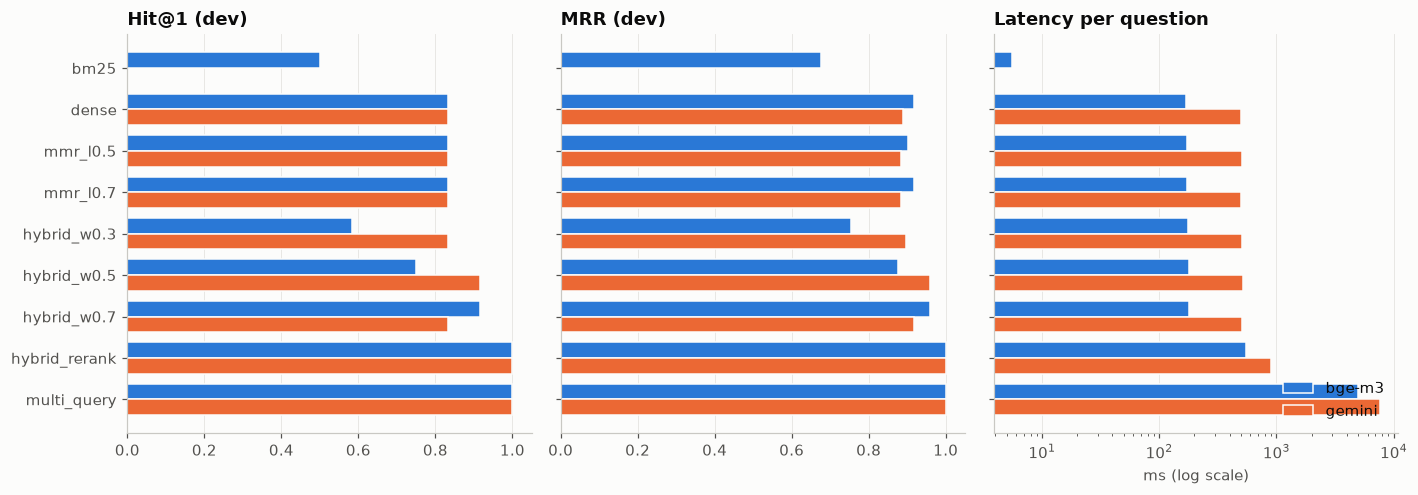

In [27]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(13, 4.6), sharey=True)
rows = range(len(order))
for k, model in enumerate(["bge-m3", "gemini"]):
    data = dev_runs[dev_runs["model"] == model].set_index("retrieval_strategy").reindex(order)
    offset = (k - 0.5) * 0.38
    for ax, col in [(ax1, "hit_at_1"), (ax2, "mrr"), (ax3, "latency_ms")]:
        ax.barh([r + offset for r in rows], data[col], height=0.38, color=SERIES[k], edgecolor=SURFACE,
                linewidth=1, label=model)
ax1.set_yticks(list(rows), order)
ax1.invert_yaxis()
ax1.set_title("Hit@1 (dev)")
ax2.set_title("MRR (dev)")
ax3.set_title("Latency per question")
ax3.set_xscale("log")
ax3.set_xlabel("ms (log scale)")
for ax in (ax1, ax2):
    ax.set_xlim(0, 1.05)
for ax in (ax1, ax2, ax3):
    ax.grid(axis="y", visible=False)
ax3.legend(loc="lower right")
fig.tight_layout()

Rank of the first gold chunk per dev question (`<NA>` = not in the top 10):

In [28]:
sweep["rank"] = (1 / sweep["reciprocal_rank"]).where(sweep["reciprocal_rank"] > 0)
sweep["model"] = sweep["embedding_model"].map(lambda m: "bge-m3" if "bge" in m else "gemini")
(sweep.pivot_table(index=["model", "strategy"], columns="question_id", values="rank")
 .reindex(order, level=1).astype("Int64"))

question_id           q001  q003  q004  q006  q008  q009  q011  q013  q015  q016  q018  q019
model  strategy                                                                             
bge-m3 bm25              1     1     1     1     7     2     7     1     1     2     3     2
       dense             1     1     1     1     1     1     1     1     2     2     1     1
       mmr_l0.5          1     1     1     1     1     1     1     1     2     3     1     1
       mmr_l0.7          1     1     1     1     1     1     1     1     2     2     1     1
       hybrid_w0.3       1     1     1     1     3     2     5     1     1     2     1     2
       hybrid_w0.5       1     1     1     1     2     1     2     1     1     2     1     1
       hybrid_w0.7       1     1     1     1     1     1     1     1     1     2     1     1
       hybrid_rerank     1     1     1     1     1     1     1     1     1     1     1     1
       multi_query       1     1     1     1     1     1     1     1     1     1     1     1
gemini dense             1     1     1     1     1     1     3     1     3     1     1     1
       mmr_l0.5          1     1     1     1     1     1     9     1     2     1     1     1
       mmr_l0.7          1     1     1     1     1     1     8     1     2     1     1     1
       hybrid_w0.3       1     1     1     1     1     1     4     1     1     2     1     1
       hybrid_w0.5       1     1     1     1     1     1     2     1     1     1     1     1
       hybrid_w0.7       1     1     1     1     1     1     2     1     2     1     1     1
       hybrid_rerank     1     1     1     1     1     1     1     1     1     1     1     1
       multi_query       1     1     1     1     1     1     1     1     1     1     1     1

### 6.3 Weak-context threshold

The bot should refuse when the papers do not contain the answer. Before generation, the score of the best passage is compared with a threshold: the reranker's probability when results are reranked, otherwise the best cosine similarity (CPU profile). The threshold is the midpoint between scores that best separates the 12 answerable dev questions from the 3 out-of-scope ones (balanced accuracy, ties to the lower value).

In [29]:
conf_dev_path = CONFIG.paths.artifacts_dir / "confidence_dev.parquet"
if RUN_EXPERIMENTS or not conf_dev_path.exists():
    conf_dev = pd.concat([confidence_table(retriever_for(kind, CONFIG), strategy, dev)
                          .assign(model=by_kind[kind].slug, strategy=strategy)
                          for kind in ("open", "commercial") for strategy in ("hybrid_rerank", "dense")])
    conf_dev.to_parquet(conf_dev_path, index=False)
else:
    conf_dev = pd.read_parquet(conf_dev_path)

calibration = pd.DataFrame([{"model": m, "strategy": s, **calibrate_threshold(t)}
                            for (m, s), t in conf_dev.groupby(["model", "strategy"])]).set_index(["model", "strategy"])
print("Thresholds in CONFIG:", CONFIG.confidence_thresholds)
calibration

Thresholds in CONFIG: {'rerank': 0.7205, 'bge_m3': 0.6091, 'gemini_embedding_001': 0.7525}


threshold  balanced_accuracy  answerable_kept  out_of_scope_flagged
model                strategy                                                                          
bge_m3               dense             0.6091              0.917            0.833                   1.0
                     hybrid_rerank     0.7205              1.000            1.000                   1.0
gemini_embedding_001 dense             0.7525              0.958            0.917                   1.0
                     hybrid_rerank     0.7205              1.000            1.000                   1.0

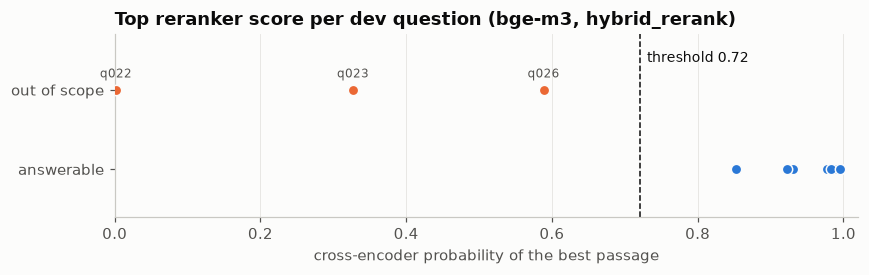

In [30]:
final_dev = conf_dev[(conf_dev["model"] == "bge_m3") & (conf_dev["strategy"] == "hybrid_rerank")]
fig, ax = plt.subplots(figsize=(8, 2.6))
for k, (answerable, label) in enumerate([(True, "answerable"), (False, "out of scope")]):
    part = final_dev[final_dev["answerable"] == answerable]
    ax.scatter(part["score"], [k] * len(part), s=46, color=SERIES[k], edgecolor=SURFACE, linewidth=1, zorder=3)
    for _, r in part.iterrows():
        if not answerable:
            ax.annotate(r["question_id"], (r["score"], k), xytext=(0, 8), textcoords="offset points",
                        ha="center", fontsize=8, color=INK_2)
ax.axvline(CONFIG.confidence_thresholds["rerank"], color=INK, linewidth=1, linestyle="--")
ax.text(CONFIG.confidence_thresholds["rerank"] + 0.01, 1.35, f"threshold {CONFIG.confidence_thresholds['rerank']:.2f}",
        fontsize=9, color=INK)
ax.set_yticks([0, 1], ["answerable", "out of scope"])
ax.set_ylim(-0.6, 1.7)
ax.set_xlim(0, 1.02)
ax.grid(axis="y", visible=False)
ax.set_title("Top reranker score per dev question (bge-m3, hybrid_rerank)")
ax.set_xlabel("cross-encoder probability of the best passage")
fig.tight_layout()

### 6.4 Paper filter and a refusal case

The paper filter restricts every strategy to chosen papers. The second query is the out-of-scope trap q027: BERT never reports its energy use, but Llama 2 reports carbon emissions, so the top passage is plausible-looking yet below the threshold.

In [31]:
final = retriever_for(CONFIG.embedding_choice, CONFIG)
strategy = CONFIG.retrieval_strategy if final.reranker else "hybrid"
demo = []
for question, papers in [("How much memory does finetuning save?", ["lora", "qlora"]),
                         ("How much electricity or CO2 did pre-training BERT consume or emit?", None)]:
    results = final.retrieve(question, strategy, paper_ids=papers)
    score, kind = final.confidence(results)
    for rank, c in enumerate(results, start=1):
        demo.append({"question": question[:45], "filter": ",".join(papers or ["all"]), "rank": rank,
                     "chunk_id": c.chunk_id, "paper_title": c.paper_title[:40], "page": c.page,
                     "rerank_score": c.rerank_score, "weak_context": final.is_weak(results)})
pd.DataFrame(demo).set_index(["question", "rank"])

filter          chunk_id                               paper_title  page  rerank_score  weak_context
question                                      rank                                                                                                          
How much memory does finetuning save?         1     lora,qlora   qlora_p001_c000  QLoRA: Efficient Finetuning of Quantized     1      0.856812         False
                                              2     lora,qlora   qlora_p001_c001  QLoRA: Efficient Finetuning of Quantized     1      0.661923         False
                                              3     lora,qlora   qlora_p004_c000  QLoRA: Efficient Finetuning of Quantized     4      0.610628         False
How much electricity or CO2 did pre-training  1            all  llama2_p007_c000  Llama 2: Open Foundation and Fine-Tuned      7      0.512761          True
                                              2            all    bert_p001_c000  BERT: Pre-training of Deep Bidirectional     1      0.198219          True
                                              3            all    bert_p013_c000  BERT: Pre-training of Deep Bidirectional    13      0.188175          True

### 6.5 Held-out results (reported once)

The final configuration was fixed before the held-out questions were scored: **bge-m3 + `hybrid_rerank`**, dense weight 0.5, weak-context threshold 0.72. The other rows give context and were not used for any choice.

In [32]:
held = load_eval_set(CONFIG.paths.eval_questions, split="held_out")
held_path = CONFIG.paths.artifacts_dir / "retrieval_heldout_per_question.parquet"
held_conf_path = CONFIG.paths.artifacts_dir / "confidence_heldout.parquet"
if RUN_EXPERIMENTS or not held_path.exists():
    held_results, held_conf = run_held_out(retriever_for, held, CONFIG)
    held_results.to_parquet(held_path, index=False)
    held_conf.to_parquet(held_conf_path, index=False)
else:
    held_results, held_conf = pd.read_parquet(held_path), pd.read_parquet(held_conf_path)

held_runs = runs[runs["split"] == "held_out"].assign(role=lambda d: d["notes"].str.replace("held-out, reported only: ", ""))
held_runs[["run_id", "role", "model", "retrieval_strategy", "hit_at_1", "hit_at_3", "hit_at_5", "mrr",
           "precision_at_3", "latency_ms"]].set_index("run_id")

,role,model,retrieval_strategy,hit_at_1,hit_at_3,hit_at_5,mrr,precision_at_3,latency_ms
run_id,,,,,,,,,
exp_036,final system,bge-m3,hybrid_rerank,0.750,1.000,1.000,0.847,0.528,563.6
exp_037,baseline,bge-m3,dense,0.667,0.833,0.833,0.736,0.472,161.0
exp_038,CPU profile (no reranker),bge-m3,hybrid,0.750,0.833,0.833,0.801,0.472,172.0
exp_039,alternative embedding,gemini,hybrid_rerank,0.833,1.000,1.000,0.889,0.556,893.5
exp_040,alternative baseline,gemini,dense,0.750,1.000,1.000,0.861,0.667,503.6


In [33]:
check = (held_conf.groupby(["role", "answerable"])["flagged_weak"].agg(flagged="sum", questions="count")
         .rename(index={True: "answerable", False: "out of scope"}, level=1))
print(check.to_string(), "\n")
held_conf[["role", "question_id", "answerable", "score", "flagged_weak", "top_is_gold"]].round(3).set_index(["role", "question_id"])

                                        flagged  questions
role                      answerable                      
CPU profile (no reranker) out of scope        2          2
                          answerable          1         12
final system              out of scope        2          2
                          answerable          0         12 



answerable  score  flagged_weak  top_is_gold
role                      question_id                                              
final system              q002               True  0.979         False         True
                          q005               True  0.997         False         True
                          q007               True  0.906         False         True
                          q010               True  1.000         False         True
                          q012               True  0.994         False        False
                          q014               True  0.980         False         True
                          q017               True  0.926         False         True
                          q020               True  0.766         False        False
                          q025              False  0.019          True        False
                          q027              False  0.513          True        False
                          q028               True  0.934         False         True
                          q029               True  0.984         False        False
                          q030               True  0.997         False         True
                          q031               True  0.997         False         True
CPU profile (no reranker) q002               True  0.664         False         True
                          q005               True  0.714         False         True
                          q007               True  0.574          True         True
                          q010               True  0.680         False         True
                          q012               True  0.753         False        False
                          q014               True  0.695         False         True
                          q017               True  0.647         False         True
                          q020               True  0.631         False        False
                          q025              False  0.503          True        False
                          q027              False  0.564          True        False
                          q028               True  0.710         False         True
                          q029               True  0.699         False        False
                          q030               True  0.720         False         True
                          q031               True  0.665         False         True

**Observations.**

- **Reranking is what matters.** `hybrid_rerank` puts a gold page first for all 12 dev questions with both embedding models (hit@1 and MRR 1.000), against hit@1 0.833 for plain dense search. On the held-out questions it lifts bge-m3 from hit@3 0.833 to 1.000 and MRR from 0.736 to 0.847. On dev it returns the same top passages whichever embedding supplied the candidates.
- **Multi-query adds nothing measurable.** It matches `hybrid_rerank` on dev but costs 4.9 s (bge-m3) to 7.6 s (Gemini) per question for the LLM rephrasings, against 0.55 s and 0.9 s. The dev set is saturated at this point, so if multi-query helps on harder questions this evaluation cannot show it.
- **MMR does not help.** Trading relevance for diversity never raises hit@1 and lowers hit@3 to 0.917 with Gemini. The papers rarely return near-duplicate chunks, so there is little redundancy to remove.
- **BM25 alone is weakest** (hit@1 0.500, MRR 0.677), but it is a useful partner: plain hybrid search beats dense at the right weight (bge-m3 with weight 0.7: MRR 0.958 vs 0.917). The best weight differs by model (0.7 for bge-m3, 0.5 for Gemini) and the spread is about one question, so the neutral 0.5 is kept instead of a value fitted to 12 questions. Under reranking the weight does not matter: the 20 candidates contain a gold page either way.
- **Weak-context threshold.** With reranking, answerable dev questions score at least 0.852 and out-of-scope ones at most 0.589 (q026, GPT-3's training cost, the hardest negative), so the midpoint 0.72 separates them perfectly. On the held-out questions it flags both out-of-scope questions, including the BERT-energy trap at 0.513, and none of the 12 answerable ones, but the margin is smaller: the lowest answerable score is 0.766 (q020). Without the reranker, cosine scores overlap: the CPU profile's threshold (0.609) flags both held-out refusals but also one answerable question (q007, 0.574).
- **Held-out vs dev.** The final system drops from hit@1 1.000 on dev to 0.750 on held-out (q012, q020 and q029 have a gold page at rank 2 or 3 rather than first), while keeping hit@3 at 1.000. Part of the dev result is fitting to 12 questions; the held-out figures are the ones to report.
- **Gemini on held-out** is one question ahead at rank 1 (hit@1 0.833, MRR 0.889 vs 0.750, 0.847). That is reported but does not reverse the choice, which was fixed before the held-out run. The experiments also ran into Gemini's free-tier limit of 1,000 embedding requests per day, which ended the session's Gemini runs for 11 hours; the embedder now stops at once with a clear message instead of retrying.
- Latency of the final configuration is about 0.55 s per question on the RTX 4060 (embedding, BM25, fusion and reranking 20 candidates), well inside the 8 s budget, which leaves room for generation.

**Decision.** Use **`hybrid_rerank` over bge-m3** (`CONFIG.retrieval_strategy = "hybrid_rerank"`, `hybrid_dense_weight = 0.5`, 20 candidates reranked to the top 3, weak-context threshold 0.72 on the reranker score). On held-out questions it reaches hit@3 1.000, hit@1 0.750 and MRR 0.847 in about 0.55 s. Without a GPU the reranker is switched off and the bot falls back to plain hybrid search with the cosine threshold 0.609; that profile is weaker (held-out hit@3 0.833, one answerable question wrongly flagged) and is documented as reduced quality. Multi-query and MMR stay available in the code but are not offered as defaults. The main limitation is the evaluation itself: with 12 dev and 12 held-out answerable questions, the strategies above plain hybrid cannot be separated further.

## 7. RAG pipeline

**Intent.** Connect the chosen retriever to the local LLM and make the answer trustworthy by construction, not by hoping the model behaves:

- **Prompt** (`rpab/prompts.py`): the rules from the technical plan (answer only from the numbered passages, cite them as [1] to [3], refuse with the exact sentence), plus two few-shot turns, one cited answer and one refusal. The examples use a made-up paper, so they teach the format without putting real facts in the prompt.
- **Chain** (`rpab/rag.py`): an LCEL chain, retriever → numbered context → prompt → `ChatOllama` (llama3.1 8B, temperature 0, `num_ctx` 8192) → text. One chain serves the streaming and the non-streaming entry points.
- **Sources** come from the retrieved chunks' metadata, never from the generated text, so a citation card cannot name a paper or page that was not retrieved.
- **Citation filter**: markers that point at no passage (`[4]` with three passages, or a paper's own reference numbers such as `[26]`) are removed, also while streaming.
- **Refusals**: an answer that opens with "I don't know", or cites nothing and says the context lacks the answer, is replaced by the exact sentence. The closest passages are still returned.
- **Weak context**: when the top reranker score is below the threshold from section 6.3, the prompt says the passages scored low and asks for a refusal unless a passage answers directly. The model still decides (the application-flow plan generates on weak context); section 8.3 shows why the notice was added.

### 7.1 Prompt

In [34]:
from rpab.config import REFUSAL_TEXT
from rpab.prompts import RAG_PROMPT, SYSTEM_PROMPT, WEAK_CONTEXT_NOTICE, format_context

print(SYSTEM_PROMPT)
print("\nWeak-context notice:" + WEAK_CONTEXT_NOTICE)
# The user turn as the model sees it, for the first held-out answerable question
example = final.retrieve(held[0]["question"], strategy)
print(RAG_PROMPT.format_messages(context=format_context(example), question=held[0]["question"],
                                 notice="")[-1].content[:900] + " …")

You are a research assistant answering questions about a fixed set of AI research papers.

Rules:
1. Answer ONLY using the numbered context passages in the user's message.
2. If the passages do not contain enough information to answer, reply exactly:
   "I don't know based on the provided papers."
   and nothing else.
3. Cite sources inline as [1], [2], [3], matching the numbered passages. Every sentence that states
   a fact from a passage ends with its citation. Never cite a number that is not in the context.
4. Do not use outside knowledge. Do not invent paper titles, page numbers or results.
5. Be concise and precise. Use technical terms as the papers use them.

Weak-context notice:
Note: these passages scored low for this question, so they may not contain the answer. Answer only if a passage states it directly; otherwise reply with the refusal sentence exactly.



Context:
[1] Paper: Attention Is All You Need | Page: 5
output values. These are concatenated and once again projected, resulting in the final values, as
depicted in Figure 2.
Multi-head attention allows the model to jointly attend to information from different representation
subspaces at different positions. With a single attention head, averaging inhibits this.
MultiHead(Q, K, V) = Concat(head1, ...,headh)W O
where headi = Attention(QW Qi , KWKi , V WVi )
Where the projections are parameter matricesW Qi ∈ Rdmodel×dk, W Ki ∈ Rdmodel×dk, W Vi ∈ Rdmodel×dv
and W O ∈ Rhdv×dmodel.
In this work we employ h = 8 parallel attention layers, or heads. For each of these we use
dk = dv = dmodel/h = 64. Due to the reduced dimension of each head, the total computational cost
is similar to that of single-head attention with full dimensionality.
3.2.3 Applications of Attention in our Model
The Transfor …


### 7.2 Citation filter

The filter runs on streamed pieces: text is held back from an unclosed `[` until the bracket closes, so a marker split across tokens is judged whole.

In [35]:
from rpab.rag import CitationFilter, is_refusal, sanitize_citations

for text in ["Adam is used [1]. Perplexity drops [4].", "Retriever DPR [26] and generator BART [32] [2].",
             "See [1, 4] and [2][5]."]:
    clean, removed = sanitize_citations(text, n_passages=3)
    print(f"{text!r:52} -> {clean!r}  removed {removed}")

pieces = ["The model", " uses", " Adam", " [", "4", "].", " It", " also", " [", "2", "]", "."]
streamed = CitationFilter(3)
print("\nstreamed:", repr("".join(streamed.feed(p) for p in pieces) + streamed.flush()), "removed", streamed.removed)

for text in [REFUSAL_TEXT, "I don\u2019t know based on the provided papers. [1]",
             "There is no mention of Mamba in the provided context passages.",
             "The paper does not mention the GPU count, but Adam is used [1]."]:
    print(f"refusal={is_refusal(text)!s:5} {text}")

'Adam is used [1]. Perplexity drops [4].'            -> 'Adam is used [1]. Perplexity drops.'  removed ['[4]']
'Retriever DPR [26] and generator BART [32] [2].'    -> 'Retriever DPR and generator BART [2].'  removed ['[26]', '[32]']
'See [1, 4] and [2][5].'                             -> 'See [1] and [2].'  removed ['[1, 4]', '[5]']

streamed: 'The model uses Adam. It also [2].' removed ['[4]']
refusal=True  I don't know based on the provided papers.
refusal=True  I don’t know based on the provided papers. [1]
refusal=True  There is no mention of Mamba in the provided context passages.
refusal=False The paper does not mention the GPU count, but Adam is used [1].


### 7.3 Streaming and latency

`RagPipeline.stream` yields the sources first (so the UI can show them while the answer is generated), then answer text, then the full `AskResponse`. `answer()` consumes the same stream. The models are warmed up first, so the timing is for a loaded system.

In [36]:
from rpab.rag import RagPipeline, make_llm
from rpab.schemas import AskRequest

pipeline = RagPipeline(final, make_llm(CONFIG), CONFIG)
pipeline.warm_up()
for event in pipeline.stream(AskRequest(question="What is a paged optimizer in QLoRA?")):
    if event["event"] == "sources":
        print(f"sources after {event['retrieval_ms']} ms (weak context: {event['weak_context']}):")
        for s in event["sources"]:
            print(f"  [{s.rank}] {s.paper_title} p.{s.page}  {s.score:.3f}")
        print()
    elif event["event"] == "token":
        print(event["text"], end="")
    else:
        response = event["response"]
print(f"\n\nfirst token {response.first_token_ms} ms, total {response.latency_ms} ms, refused={response.refused}")
response.model_dump(exclude={"sources"})

sources after 742 ms (weak context: False):
  [1] QLoRA: Efficient Finetuning of Quantized LLMs p.4  0.907
  [2] QLoRA: Efficient Finetuning of Quantized LLMs p.2  0.848
  [3] QLoRA: Efficient Finetuning of Quantized LLMs p.1  0.829



A Paged

 Optimizer, as

 used in QL

 ORA,

...

 mini-batch with

 a long sequence

 length

 [2].

first token 2636 ms, total 5590 ms, refused=False


{'answer': 'A Paged Optimizer, as used in QL ORA, uses NVIDIA unified memory to avoid the gradient checkpointing memory spikes that occur when processing a mini-batch with a long sequence length [2].',
 'refused': False,
 'rewritten_question': None,
 'strategy_used': 'hybrid_rerank',
 'latency_ms': 5590,
 'used_web_fallback': False,
 'web_note': None,
 'weak_context': False,
 'retrieval_ms': 742,
 'rewrite_ms': None,
 'first_token_ms': 2636,
 'removed_citations': []}

## 8. Evaluation and failure analysis

**Intent.** Score the answers, not just the retrieval, on the four dimensions of the plan, and check whether an LLM judge can stand in for manual scoring.

- **Rubric** (`RUBRIC` in `rpab/answer_eval.py`): relevance, accuracy (against the eval set's reference answer) and groundedness (share of claims supported by the three passages) from 1 to 5, and hallucination when any claim is not supported by the passages, even a true one. A refusal scores 5/5/5 on an out-of-scope question and fails relevance and accuracy on an answerable one.
- **Manual scores** (`data/eval/answer_scores_manual.csv`) cover all 29 questions for llama3.1 8B. They were drafted by Claude, checking each claim against the passages, and then reviewed and corrected by the author; the `scored_by` column records which rows were reviewed.
- **Judge**: `qwen2.5:7b` at temperature 0 in JSON mode, given the same rubric, the question, the reference answer, the passages and the answer. It is a different model family from the generator, so it does not grade its own style.
- **Reporting**: answers are generated for all 29 questions, but the final scores are the held-out ones (14 questions: 12 answerable, 2 out of scope).

### 8.1 Answers

In [37]:
from rpab.answer_eval import (DIMENSIONS, agreement, load_manual_scores, load_or_generate, load_or_judge,
                              model_slug, score_summary)

questions = load_eval_set(CONFIG.paths.eval_questions)
SMALL_LLM = "llama3.2:3b"  # the CPU profile's model
answers, judged = {}, {}
for model in [CONFIG.llm_model, SMALL_LLM]:
    pipe = pipeline if model == CONFIG.llm_model else RagPipeline(final, make_llm(CONFIG, model), CONFIG)
    if RUN_EXPERIMENTS:
        pipe.warm_up()
    answers[model] = load_or_generate(pipe, questions, CONFIG.paths.answers_dir / f"{model_slug(model)}.parquet",
                                      rerun=RUN_EXPERIMENTS)
    judged[model] = load_or_judge(answers[model], CONFIG,
                                  CONFIG.paths.answers_dir / f"judge_{model_slug(model)}.parquet", rerun=RUN_EXPERIMENTS)
main_answers = answers[CONFIG.llm_model]
main_answers[["question_id", "split", "answerable", "weak_context", "refused", "answer", "first_token_ms",
              "latency_ms"]].set_index("question_id")

,split,answerable,weak_context,refused,answer,first_token_ms,latency_ms
question_id,,,,,,,
q001,dev,True,False,False,"The dot products grow large in magnitude for large values of dk, pushing the softmax f...",2366,5465
q002,held_out,True,False,False,"The Transformer uses 8 parallel attention layers, or heads [1]. For each of these, dk ...",1760,3764
q003,dev,True,False,False,15% of all WordPiece tokens in each sequence at random are chosen for prediction [2]. ...,1929,7118
q004,dev,True,False,False,"Dense Passage Retrieval uses in-batch negative training, where each question in the ba...",2008,8250
q005,held_out,True,False,False,"On Natural Questions, DPR reaches a top-20 retrieval accuracy of 69.9%, while BM25 ach...",1753,3715
q006,dev,True,False,False,The main difference between the two models is that RAG-Sequence uses the same retrieve...,1903,6328
q007,held_out,True,False,False,"The RAG model combines a pre-trained neural retriever, specifically the Dense Passage ...",1896,5092
q008,dev,True,False,False,"The 175B GPT-3 model has 96 layers [1], a model dimension of 12288 [1], and 96 attenti...",1970,4167
q009,dev,True,False,False,The LoRA matrices A and B are initialized with a random Gaussian initialization for A ...,1789,4414


### 8.2 Manual scores (held-out)

In [38]:
manual = load_manual_scores(CONFIG.paths.manual_scores)
print(f"{(manual['scored_by'] != 'claude_draft').sum()} of {len(manual)} rows reviewed by the author")
split_of = main_answers.set_index("question_id")["split"]
pd.DataFrame({split: score_summary(manual[manual["question_id"].map(split_of) == split],
                                   main_answers[main_answers["split"] == split])
              for split in ["held_out", "dev"]})

29 of 29 rows reviewed by the author


,held_out,dev
relevance,4.928571,4.8
accuracy,4.357143,4.466667
groundedness,4.642857,4.733333
hallucination_rate,0.142857,0.133333
correct_refusals,2/2,3/3
wrong_refusals,0/12,0/12
median_first_token_ms,1855.5,1929.0
median_latency_ms,5005.5,5052.0


### 8.3 Effect of the weak-context notice

The first round of answers (kept in `artifacts/answers/round1/`) used the same prompt without the notice. Refusal counts and judge accuracy, all 29 questions:

In [39]:
round1_dir = CONFIG.paths.answers_dir / "round1"
rows = []
for model in [CONFIG.llm_model, SMALL_LLM]:
    for label, folder in [("without notice", round1_dir), ("with notice", CONFIG.paths.answers_dir)]:
        a = pd.read_parquet(folder / f"{model_slug(model)}.parquet")
        s = score_summary(pd.read_parquet(folder / f"judge_{model_slug(model)}.parquet"), a)
        rows.append({"model": model, "prompt": label, "correct_refusals": s["correct_refusals"],
                     "wrong_refusals": s["wrong_refusals"], "judge_accuracy": round(s["accuracy"], 2)})
pd.DataFrame(rows).set_index(["model", "prompt"])

correct_refusals wrong_refusals  judge_accuracy
model           prompt                                                        
llama3.1:latest without notice              2/5           0/24            4.41
                with notice                 5/5           0/24            4.72
llama3.2:3b     without notice              4/5           2/24            4.28
                with notice                 5/5           3/24            4.55

### 8.4 LLM judge vs manual scores

Exact and within-one agreement, quadratic-weighted Cohen's kappa (1 = perfect, 0 = chance), and the judge's mean offset (positive = more lenient), over all 29 llama3.1 answers:

In [40]:
judge_main = judged[CONFIG.llm_model]
display(agreement(manual, judge_main).round(3))

pairs = manual.merge(judge_main, on="question_id", suffixes=("_manual", "_judge"))
gap = pd.concat([(pairs[f"{d}_manual"] - pairs[f"{d}_judge"]).abs() for d in DIMENSIONS], axis=1).max(axis=1)
disagree = pairs[(gap > 1) | (pairs["hallucination_manual"] != pairs["hallucination_judge"])]
disagree[["question_id"] + [f"{d}_{w}" for d in DIMENSIONS + ["hallucination"] for w in ("manual", "judge")]
         + ["reason"]].set_index("question_id")

,questions,exact,within_1,kappa_quadratic,judge_minus_manual
dimension,,,,,
relevance,29,0.828,0.966,0.493,-0.138
accuracy,29,0.724,0.966,0.759,0.310
groundedness,29,0.793,0.931,0.446,0.069
hallucination,29,0.897,NaN,0.365,-0.103


,relevance_manual,relevance_judge,accuracy_manual,accuracy_judge,groundedness_manual,groundedness_judge,hallucination_manual,hallucination_judge,reason
question_id,,,,,,,,,
q004,4,5,3,4,4,4,True,False,The answer addresses the question and is mostly accurate but omits that gold negatives...
q005,4,3,1,2,2,4,True,True,The answer addresses part of the question but provides incorrect accuracy values.
q018,5,3,3,4,3,4,True,False,The answer addresses part of the question but omits the token count.
q030,5,5,3,5,3,5,True,False,The answer fully addresses the question and is accurate and grounded in the provided p...


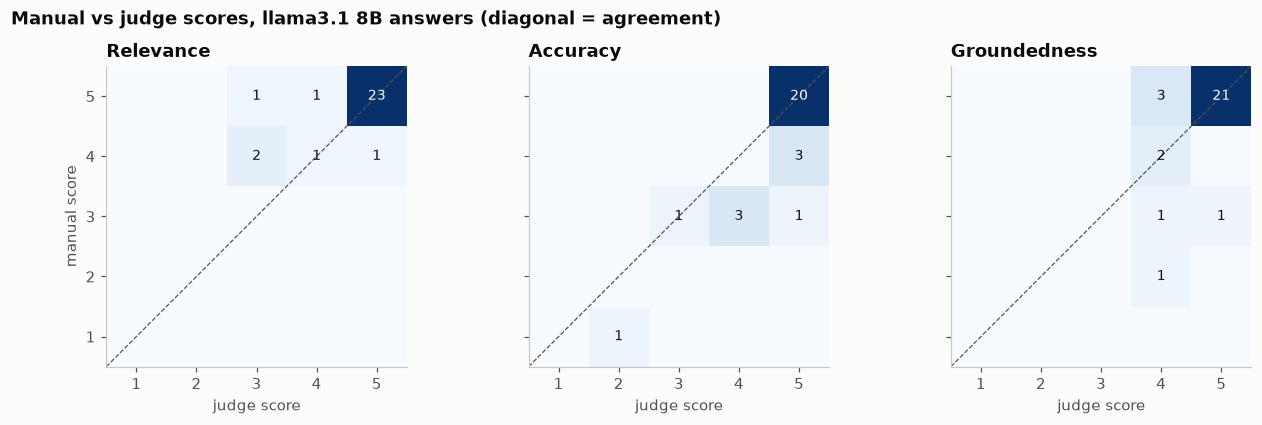

In [41]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), sharey=True)
for ax, d in zip(axes, DIMENSIONS):
    counts = pd.crosstab(pairs[f"{d}_manual"], pairs[f"{d}_judge"]).reindex(index=range(1, 6), columns=range(1, 6),
                                                                              fill_value=0)
    ax.imshow(counts, cmap="Blues", origin="lower", extent=(0.5, 5.5, 0.5, 5.5))
    for (m, j), n in counts.stack().items():
        if n:
            ax.text(j, m, n, ha="center", va="center", fontsize=9, color=SURFACE if n > 8 else INK)
    ax.plot([0.5, 5.5], [0.5, 5.5], color=INK_2, linewidth=0.8, linestyle="--")
    ax.set_title(d.capitalize())
    ax.set_xlabel("judge score")
    ax.grid(visible=False)
axes[0].set_ylabel("manual score")
fig.suptitle("Manual vs judge scores, llama3.1 8B answers (diagonal = agreement)", x=0.01, ha="left",
             fontweight="bold")
fig.tight_layout()

### 8.5 Failure log

Every answer with a failure cause, using the plan's categories (`retrieval_miss`, `bad_chunk`, `ambiguous_question`, `ignored_context`, `other`):

In [42]:
failures = (manual[manual["failure_cause"].notna()]
            .merge(main_answers[["question_id", "split", "gold_in_context"]], on="question_id"))
print(failures["failure_cause"].value_counts().to_string())
failures[["question_id", "split", "failure_cause", "relevance", "accuracy", "groundedness", "hallucination",
          "gold_in_context", "notes"]].set_index("question_id")

failure_cause
ignored_context    5
retrieval_miss     1


,split,failure_cause,relevance,accuracy,groundedness,hallucination,gold_in_context,notes
question_id,,,,,,,,
q004,dev,ignored_context,4,3,4,True,True,"Now gets the key idea (negatives reused from the same batch), but still opens with the..."
q005,held_out,ignored_context,4,1,2,True,True,Gives 69.9% vs 55.0% (WebQuestions cross-dataset numbers from [2]) as Natural Question...
q015,dev,ignored_context,4,3,5,False,True,Describes quantile quantization correctly but omits what makes NF4 'normal': optimal f...
q018,dev,retrieval_miss,5,3,3,True,True,"Context length 2048 to 4096 is right, but '150B tokens' is the context-length ablation..."
q019,dev,ignored_context,4,3,4,False,True,"Gets the 4-bit quantized frozen model, but not NF4, double quantization or dequantizin..."
q030,held_out,ignored_context,5,3,3,True,True,"Preference for 1.3B InstructGPT over 175B GPT-3 is right, but attaches '85 +/- 3%', wh..."


### 8.6 Refusals on out-of-scope questions

In [43]:
main_answers[~main_answers["answerable"]][["question_id", "split", "question", "weak_context", "refused",
                                           "answer"]].set_index("question_id")

,split,question,weak_context,refused,answer
question_id,,,,,
q022,dev,How does the denoising U-Net in Stable Diffusion work?,True,True,I don't know based on the provided papers.
q023,dev,How many parameters does GPT-4 have according to its technical report?,True,True,I don't know based on the provided papers.
q025,held_out,How does Mamba's selective state space model replace attention?,True,True,I don't know based on the provided papers.
q026,dev,How much did it cost in US dollars to train GPT-3 175B?,True,True,I don't know based on the provided papers.
q027,held_out,How much electricity or CO2 did pre-training BERT consume or emit?,True,True,I don't know based on the provided papers.


### 8.7 llama3.1 8B vs llama3.2 3B

The CPU profile runs `llama3.2:3b` because the 8B model is too slow without a GPU (measured during setup: about 90 s per answer on the CPU). Both models answer from the same retrieved passages, so this isolates the generator. Judge scores on the held-out questions; latency on the GPU:

In [44]:
display(pd.DataFrame({model: score_summary(judged[model], answers[model][answers[model]["split"] == "held_out"])
                      for model in [CONFIG.llm_model, SMALL_LLM]}))
small = answers[SMALL_LLM]
wrong = small[small["answerable"] & small["refused"]]
print(f"{SMALL_LLM} refused {len(wrong)} answerable question(s):", ", ".join(wrong["question_id"]))

,llama3.1:latest,llama3.2:3b
relevance,4.785714,4.5
accuracy,4.785714,4.571429
groundedness,4.785714,4.642857
hallucination_rate,0.071429,0.071429
correct_refusals,2/2,2/2
wrong_refusals,0/12,1/12
median_first_token_ms,1855.5,1043.0
median_latency_ms,5005.5,1460.0


llama3.2:3b refused 3 answerable question(s): q008, q019, q030


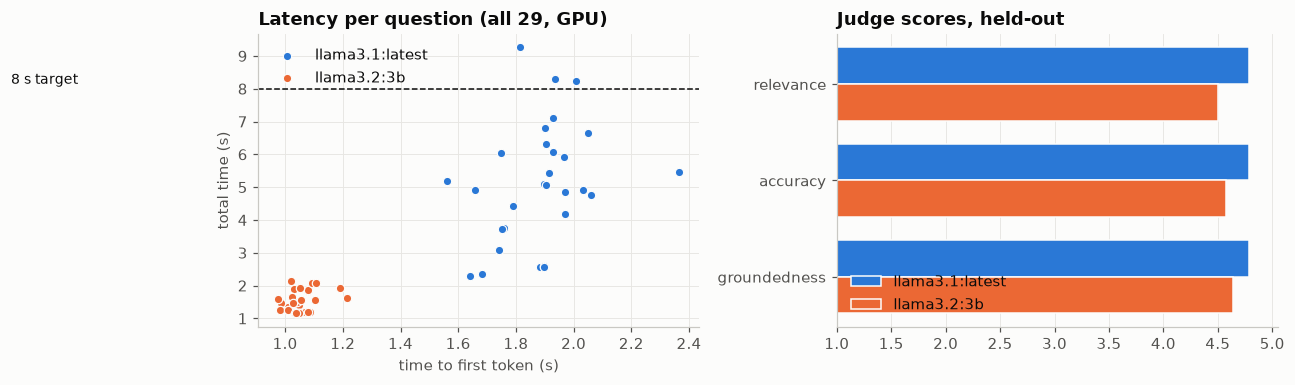

In [45]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.6))
for k, model in enumerate([CONFIG.llm_model, SMALL_LLM]):
    a = answers[model]
    ax1.scatter(a["first_token_ms"] / 1000, a["latency_ms"] / 1000, s=30, color=SERIES[k], edgecolor=SURFACE,
                linewidth=0.8, label=model, zorder=3)
    means = judged[model].merge(a[["question_id", "split"]], on="question_id")
    means = means[means["split"] == "held_out"][DIMENSIONS].mean()
    ax2.barh([i + (k - 0.5) * 0.38 for i in range(3)], means, height=0.38, color=SERIES[k], edgecolor=SURFACE,
             label=model)
ax1.axhline(8, color=INK, linewidth=1, linestyle="--")
ax1.text(0.05, 8.15, "8 s target", fontsize=9, color=INK)
ax1.set_xlabel("time to first token (s)")
ax1.set_ylabel("total time (s)")
ax1.set_title("Latency per question (all 29, GPU)")
ax1.legend(loc="upper left")
ax2.set_yticks(range(3), DIMENSIONS)
ax2.invert_yaxis()
ax2.set_xlim(1, 5.05)
ax2.grid(axis="y", visible=False)
ax2.set_title("Judge scores, held-out")
ax2.legend(loc="lower left")
fig.tight_layout()

**Observations.** All 29 manual scores have been reviewed by the author (see 8.2).

- **Held-out answers (llama3.1 8B, manual):** relevance 4.93, accuracy 4.36, groundedness 4.64 out of 5. 2 of the 14 answers contain a hallucination, both answerable questions; both out-of-scope questions are refused and no answerable question is. Dev scores are within 0.15 of these, so the prompt was not fitted to the dev questions.
- **The weak-context notice fixed refusals.** Without it llama3.1 refused only 2 of the 5 out-of-scope questions: it answered q026 (GPT-3's cost in dollars) with the compute figure in petaflop/s-days, q027 with Llama 2's carbon numbers, and refused q025 in its own words, which the refusal check then missed. With the notice it refuses all 5 and still refuses none of the 24 answerable questions, because none of them is flagged as weak. The refusal check now also accepts uncited "there is no mention of …" answers.
- **The typical error is a neighbouring number, not an invented one.** Every answerable question had a gold page among its three passages, yet five answers lost accuracy for `ignored_context`: q005 reports DPR's WebQuestions figures (69.9 vs 55.0) as its Natural Questions result, which the top passage states as 78.4 vs 59.1; q030 attaches the 175B model's 85% preference to the 1.3B model; q004, q015 and q019 leave out the defining detail even though a passage holds it. The one `retrieval_miss` (q018) is the Llama 2 token count: the retrieved appendix page mentions a 150B-token ablation, the page saying 2 trillion was not retrieved, and the model used the number it had.
- **Citations.** The filter removed markers in 3 answers, all of them the paper's own reference numbers that the model copied from the passage text ([26] for DPR, [32] for BART, [15]). Sources are built from metadata, so the cards were right in every case, but the model sometimes cites the wrong passage number for a correct sentence (q006, q015, q017). That is a limitation of an 8B model's citation discipline, not of the source cards.
- **The judge is usable for accuracy, not for hallucination.** qwen2.5:7b agrees with the manual accuracy score within one point on 97% of answers (quadratic kappa 0.76) and is about 0.3 points more lenient. On groundedness and relevance agreement is only moderate (kappa 0.45 and 0.49), and it flags just 1 of the 4 hallucinations: it accepts a wrong number when the same number appears somewhere in the passages (q018, q030). Without the manual scores this weakness would not be visible.
- **8B vs 3B.** On the held-out questions the judge rates llama3.2 3B 0.15 to 0.3 points lower on every dimension, with the same hallucination rate, and it refuses one answerable held-out question (three of 24 overall: q008, q019, q030). It is 3.4× faster on the GPU (median 1.5 s vs 5.0 s).
- **Latency.** llama3.1 shows the first token after 1.9 s (median; never more than 2.4 s) and finishes in 5.0 s; 3 of 29 answers take longer than 8 s (up to 9.3 s), all long multi-sentence answers. About a quarter of the 8B model runs on the CPU, because bge-m3 and the reranker hold about 2.4 GB of the 8 GB GPU. Streaming hides most of it: the sources appear after 0.5 s and text after about 2 s.

**Decision.** The bot answers with **llama3.1 8B and the weak-context notice**: on held-out questions it is grounded, refuses correctly, and streams its first token in under 2.5 s, with the 8 s budget exceeded only by long answers. `qwen2.5:7b` is kept as a relative measure (it ranks the two generators and the two prompt variants consistently with the manual scores) but is not trusted to find hallucinations, so manual scoring stays the reference. The CPU profile's **llama3.2 3B is supported as reduced quality**: slightly lower scores and the occasional wrong refusal, which the setup script already labels. The main limitation is the size of the evaluation: 14 held-out questions, so one answer moves a mean by about 0.3 points.

## 9. Stretch goals

**Intent.** All three stretch goals from the brief are implemented in `backend/rpab` and shared by the notebook, the Streamlit app and the API: **S1** conversational memory, **S2** a user interface (a Streamlit app, plus a Next.js app over a FastAPI service), and **S3** corrective RAG with a web search fallback. Each subsection shows the feature working on the real pipeline and states its limits. Like the other slow or networked runs, the S1 and S3 results are saved in `artifacts/` and reloaded unless `RUN_EXPERIMENTS` is `True`; the web results in particular change from one day to the next.

### 9.1 S1: conversational memory

`rpab.memory` keeps each chat in SQLite (`artifacts/chat.db`, with the `sessions`, `messages` and `message_sources` tables from doc 05) and wraps the pipeline in a `Conversation`. Before retrieval, llama3.1 rewrites a follow-up into a standalone question from the last 6 messages, and retrieval and the answer use only that rewrite (doc 03, section 5). Earlier follow-ups appear in the history in their rewritten form, so unresolved references do not pile up. The rewrite prompt's few-shot examples come from the same fictional paper as the answer prompt's, so they teach the format without real facts.

A five-turn conversation, in a throw-away database so the notebook leaves no chat behind:

In [46]:
import json
import tempfile
import textwrap

from rpab.memory import ChatStore, Conversation, QuestionRewriter

CONVERSATION = ["What is LoRA?", "How does QLoRA build on it?", "What data type does it introduce?",
                "How many attention heads does the Transformer base model use?", "And the big one?"]
s1_path = CONFIG.paths.artifacts_dir / "s1_conversation.json"
if RUN_EXPERIMENTS or not s1_path.exists():
    with tempfile.TemporaryDirectory() as tmp:
        chat = Conversation(pipeline, ChatStore(Path(tmp) / "chat.db"), CONFIG)
        s1_turns = []
        for question in CONVERSATION:
            r = chat.answer(AskRequest(question=question, session_id="notebook-s1"))
            top = r.sources[0]
            s1_turns.append({"question": question, "searched_as": r.rewritten_question, "rewrite_ms": r.rewrite_ms,
                             "top_source": f"{top.paper_title.split(':')[0]}, p. {top.page}", "refused": r.refused,
                             "answer": r.answer})
    s1_path.write_text(json.dumps(s1_turns, indent=1, ensure_ascii=False), encoding="utf-8")
s1 = pd.DataFrame(json.loads(s1_path.read_text(encoding="utf-8")))
s1.assign(answer=s1["answer"].str.slice(0, 110) + "…").set_index("question")

,searched_as,rewrite_ms,top_source,refused,answer
question,,,,,
What is LoRA?,What is LoRA?,NaN,"LoRA, p. 2",False,LoRA (Low-Rank Adaptation) is a method that reduces memory requirements by using a sma...
How does QLoRA build on it?,How does QLoRA build on LoRA?,1458.0,"QLoRA, p. 4",False,QLoRA builds on LoRA by quantizing the transformer model to 4-bit precision and using ...
What data type does it introduce?,What data type does QLoRA introduce?,1426.0,"QLoRA, p. 4",False,"QLORA introduces two new data types: 4-bit NormalFloat (NF4), which is an information ..."
How many attention heads does the Transformer base model use?,How many attention heads does the Transformer base model use?,1488.0,"Attention Is All You Need, p. 5",False,"The Transformer uses multi-head attention with h = 8 parallel attention layers, or hea..."
And the big one?,How many attention heads does the Transformer base model use?,1602.0,"Attention Is All You Need, p. 5",False,"The Transformer uses multi-head attention with h = 8 parallel attention layers, or hea..."


The rewriter on its own, on eight hand-written follow-ups: three histories (LoRA, the Transformer, QLoRA) and a mix of pronouns, an elliptical fragment, a vague reference and two questions that are already standalone:

In [47]:
LORA = [("user", "What is LoRA?"),
        ("assistant", "LoRA freezes the pretrained model weights and injects trainable rank decomposition matrices "
                      "into each layer of the Transformer [1].")]
HEADS = [("user", "How many attention heads does the Transformer base model use?"),
         ("assistant", "The base model uses h = 8 parallel attention heads [1].")]
QLORA = LORA + [("user", "How does QLoRA build on LoRA?"),
                ("assistant", "QLoRA backpropagates gradients through a frozen 4-bit quantized model into LoRA adapters [1].")]
REWRITE_CASES = [("LoRA", LORA, "What rank did they use for GPT-3?"), ("Transformer", HEADS, "And the big one?"),
                 ("QLoRA", QLORA, "What data type does it introduce?"), ("LoRA", LORA, "What is the capital of France?"),
                 ("Transformer", HEADS, "How was BERT pre-trained?"), ("QLoRA", QLORA, "How much memory does that save?"),
                 ("LoRA", LORA, "Who wrote it?"), ("Transformer", HEADS, "What dropout rate?")]
rewrites_path = CONFIG.paths.artifacts_dir / "s1_rewrites.json"
if RUN_EXPERIMENTS or not rewrites_path.exists():
    rewriter = QuestionRewriter(pipeline.llm)
    rewrite_rows = [{"history": topic, "follow_up": q, "rewritten": rewriter.rewrite(history, q)}
                    for topic, history, q in REWRITE_CASES]
    rewrites_path.write_text(json.dumps(rewrite_rows, indent=1, ensure_ascii=False), encoding="utf-8")
pd.DataFrame(json.loads(rewrites_path.read_text(encoding="utf-8"))).set_index(["history", "follow_up"])

,,rewritten
history,follow_up,
LoRA,What rank did they use for GPT-3?,What rank did the authors use for GPT-3?
Transformer,And the big one?,How many attention heads does the big Transformer model use?
QLoRA,What data type does it introduce?,What data type does QLoRA introduce?
LoRA,What is the capital of France?,What is the capital of France?
Transformer,How was BERT pre-trained?,How was BERT pre-trained?
QLoRA,How much memory does that save?,How much memory does QLoRA save compared to the original model?
LoRA,Who wrote it?,Who wrote the Low-Rank Adaptation paper?
Transformer,What dropout rate?,What is the dropout rate used in the Transformer base model?


**Observations (S1).**

- **Follow-ups are resolved before retrieval.** In the conversation, "How does QLoRA build on it?" and "What data type does it introduce?" become "…on LoRA?" and "…does QLoRA introduce?", and both are answered from QLoRA's pages. The first question has no history, so it is used as typed.
- **The window needed a recency signal.** The first version gave the rewriter the last 6 messages as one block. In the demo of section 10, "What data type does it use for the frozen weights?", asked after three topics, went to the first topic (RAG) instead of the last (LoRA vs QLoRA), apparently pulled by the wording of the RAG answer. With earlier answers in the history it went to RAG in 2 of 4 runs (once with the single block, once after the most recent exchange was labelled separately). The rewriter now sees the earlier *questions* only, plus the most recent question and answer in full, and the same follow-up resolved to QLoRA in 5 of 5 runs (3 through the API, the demo rehearsal and this notebook).
- **Hand-written cases: 7 of 8 resolve.** Pronouns, vague references ("that") and fragments ("What dropout rate?") gain the right subject, and standalone questions are left alone. The miss is "What rank did they use for GPT-3?", where "they" became "the authors"; with GPT-3 named in the question, "they" is genuinely ambiguous.
- **Known limit: an elliptical qualifier can be lost.** On its own, "And the big one?" becomes "How many attention heads does the big Transformer model use?"; inside the conversation above it lost "big" and asked about the base model again, so the answer repeats h = 8 (the big model uses 16). An 8B rewriter at temperature 0 is not perfectly repeatable on this setup: in an earlier run of the same cell, the answer to the heads question took BERT's 12 heads from the second passage, the neighbouring-number failure of section 8.5.
- **Cost.** Rewriting takes 1.4–1.6 s per follow-up here. Every question after the first one in a session is rewritten, even a standalone one.

**Decision.** Keep the rewriter with the two-part history (earlier questions, then the latest exchange in full) and the 6-message window. Retrieval always uses the rewritten question, and both apps show it as "Searched as", so a wrong rewrite is visible rather than silent.

### 9.2 S2: the apps

Both apps follow the design mockup (`plan/SampleUI.html`): chats and settings on the left, the conversation in the middle, and a reader on the right that shows a cited passage on its page, with the sentence the answer drew on highlighted, or the paper library, whose checkboxes limit the search.

- **Streamlit** (`frontend/streamlit`) runs the pipeline in-process (`st.cache_resource`) and streams the answer.
- **Next.js** (`frontend/web`, TypeScript and Tailwind) runs over the FastAPI service (`backend/api`): `POST /ask/stream` sends the sources, then the answer token by token, as Server-Sent Events.

Both show every state of the mockup (empty, loading steps, answer, follow-up, refusal with the closest passages, error with the question kept, no index), save chats so a reload continues them, and offer light and dark themes. They were checked in a real browser (Edge, driven by Playwright) against the live models, light and dark, at desktop, tablet and phone widths.

The Next.js app after a question: the three source cards, the answer with its citation chips, and the reader showing the cited page with the sentence the answer drew on highlighted:

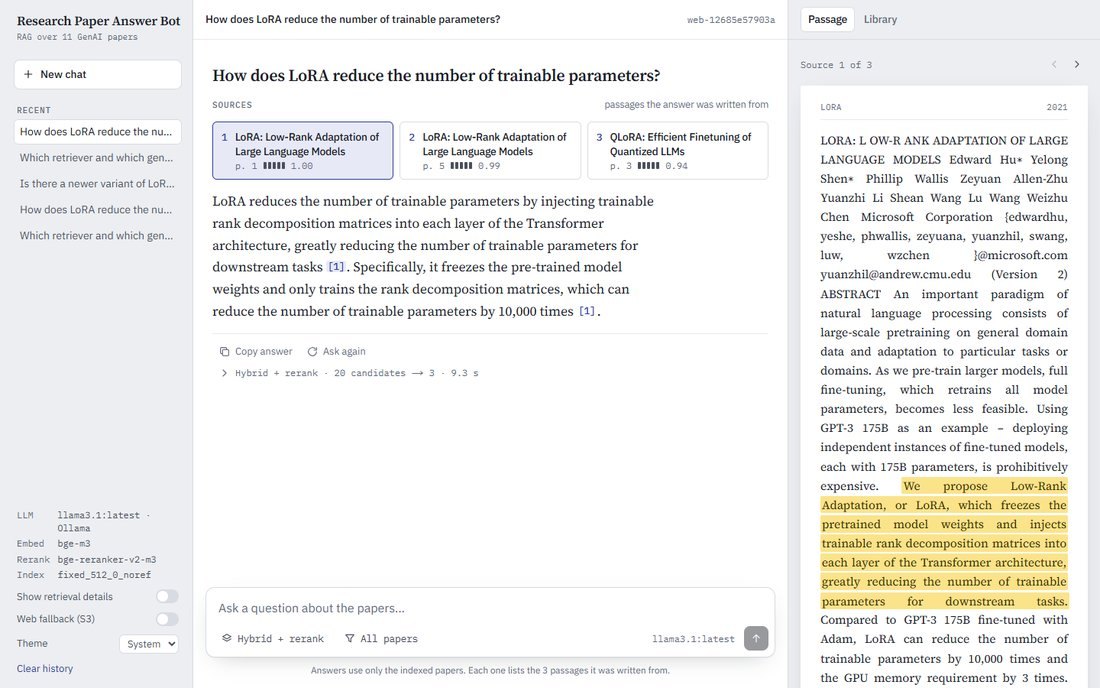

The Streamlit app on the same layout:

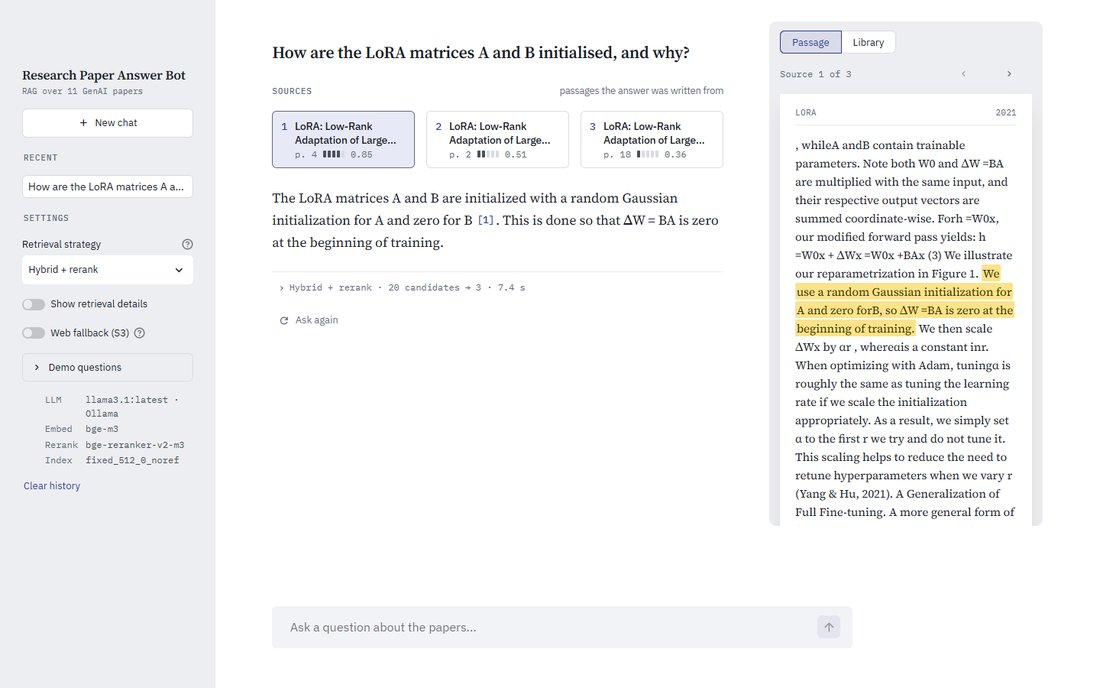

### 9.3 S3: corrective RAG with a web fallback

`rpab.crag` is off by default and turned on per request. When it is on and the best paper passage scores below the calibrated weak-context threshold (0.72 on the reranker score, section 6.3), the question is also sent to DuckDuckGo (no API key). The reranker scores the web snippets against the question together with the paper passages and the best three are kept, so a web result is used only when it beats the papers. Web passages are marked `Web` in the prompt, carry `origin="web"` and their address in the sources, and the response's `web_note` says why the web was searched; a failed search falls back to the papers alone.

Three questions, each with the fallback off and on: one the papers cannot answer but the web can, one of the evaluation's out-of-scope questions, and one the papers answer well:

In [48]:
from rpab.crag import WebSearch
from rpab.rag import RagPipeline

CRAG_QUESTIONS = ["Is there a newer variant of LoRA that also adapts weight magnitude?",
                  "How does Mamba's selective state space model replace attention?",
                  "How are the LoRA matrices A and B initialised, and why?"]
crag_path = CONFIG.paths.artifacts_dir / "s3_crag_demo.json"
if RUN_EXPERIMENTS or not crag_path.exists():
    web_pipeline = RagPipeline(final, pipeline.llm, CONFIG, web=WebSearch(CONFIG.web_results, CONFIG.web_timeout_s))
    crag_rows = []
    for question in CRAG_QUESTIONS:
        for web in (False, True):
            r = web_pipeline.answer(AskRequest(question=question, web_fallback=web))
            crag_rows.append({"question": question, "web_fallback": web, "refused": r.refused,
                              "web_sources": sum(s.origin == "web" for s in r.sources),
                              "top_score": round(r.sources[0].score, 3), "latency_ms": r.latency_ms,
                              "web_note": r.web_note, "answer": r.answer,
                              "sources": [f"[{s.rank}] {s.paper_title[:60]}, " + (s.url if s.origin == "web" else f"p. {s.page}")
                                          for s in r.sources]})
    crag_path.write_text(json.dumps(crag_rows, indent=1, ensure_ascii=False), encoding="utf-8")
crag = pd.DataFrame(json.loads(crag_path.read_text(encoding="utf-8")))
crag.assign(question=crag["question"].str.slice(0, 48))[
    ["question", "web_fallback", "refused", "web_sources", "top_score", "latency_ms"]].set_index(["question", "web_fallback"])

refused  web_sources  top_score  latency_ms
question                                         web_fallback                                             
Is there a newer variant of LoRA that also adapt False            True            0      0.510        9623
                                                 True            False            3      0.849        7054
How does Mamba's selective state space model rep False            True            0      0.019        8406
                                                 True            False            3      0.989        4930
How are the LoRA matrices A and B initialised, a False           False            0      0.852        4875
                                                 True            False            0      0.852        2501

In [49]:
for row in crag[crag["web_fallback"]].itertuples():
    print(row.question)
    print("  note:", row.web_note or "no web search: the papers matched well enough")
    print("  answer:", textwrap.shorten(row.answer, 300))
    for line in row.sources:
        print("   ", line)
    print()

Is there a newer variant of LoRA that also adapts weight magnitude?
  note: The best paper passage scored 0.51, below the 0.72 threshold, so the question was also sent to a web search (DuckDuckGo). 3 of the 3 passages come from the web and are marked WEB.
  answer: Yes, DoRA (Weight-Decomposed Low-Rank Adaptation) is a newer variant of LoRA that decomposes the pre-trained weight into its magnitude and directional components and fine-tunes both [2]. It specifically employs LoRA for directional updates to efficiently minimize the number of trainable [...]
    [1] Introducing DoRA, a High-Performing Alternative to LoRA for , https://developer.nvidia.com/blog/introducing-dora-a-high-performing-alternative-to-lora-for-fine-tuning/
    [2] DoRA: Weight-Decomposed Low-Rank Adaptation - arXiv.org, https://arxiv.org/html/2402.09353v4
    [3] Weight-Decomposed LoRA (DoRA) - emergentmind.com, https://www.emergentmind.com/topics/weight-decomposed-lora-dora

How does Mamba's selective state space m

**Observations (S3).**

- **It recovers questions the papers cannot answer.** The DoRA question is refused without the fallback (best paper passage 0.51, below 0.72). With it, the three DuckDuckGo snippets outscore every paper passage (top 0.85), so all three sources are web results, each marked and linked, and the answer cites them.
- **It also answers out-of-scope questions, which is why it is off by default.** The Mamba question is one of the evaluation's out-of-scope questions: refused without the fallback (0.02), answered from the web with it (0.99). For a bot meant to answer *from these papers*, the refusal is the correct behaviour, so the evaluation in section 8 runs with the fallback off and the apps keep it behind a switch, with a notice that the question leaves the machine.
- **It stays out of the way when the papers suffice.** The LoRA initialisation question scores 0.85 on its own and is never sent to the web; the answer is the same either way.
- **Limits.** Web snippets are short (about 300 characters) and change from day to day, so these results are saved from one run rather than recomputed. The rerank score of a snippet measures relevance, not reliability.

**Decision.** Ship S3 as an opt-in feature with clear labelling, and report every number in this notebook with it off.

## 10. Final demo

**Intent.** The demo script of doc 03 (section 10) run end to end through the same `Conversation` the apps use: a factual lookup, a method detail, a cross-paper comparison, a follow-up that needs the conversation, an out-of-scope question, and one more numeric question. All six run in one session, so question 4 is resolved from question 3. This cell runs live on every execution: each answer below comes with the three passages it was written from, by paper title and page.

In [50]:
DEMO = [("Factual lookup", "Which retriever and which generator does the RAG model combine?"),
        ("Method detail", "How are the LoRA matrices A and B initialised, and why?"),
        ("Cross-paper comparison", "How do LoRA and QLoRA differ in how they keep the frozen pretrained weights?"),
        ("Follow-up (S1)", "What data type does it use for the frozen weights?"),
        ("Out of scope", "How does Mamba's selective state space model replace attention?"),
        ("Numeric detail", "At what model scale does chain-of-thought prompting start to improve performance?")]

with tempfile.TemporaryDirectory() as tmp:
    demo_chat = Conversation(pipeline, ChatStore(Path(tmp) / "chat.db"), CONFIG)
    demo = [(kind, q, demo_chat.answer(AskRequest(question=q, session_id="notebook-demo"))) for kind, q in DEMO]

for k, (kind, question, r) in enumerate(demo, start=1):
    print(f"{k}. [{kind}] {question}")
    if r.rewritten_question and r.rewritten_question != question:
        print(f"   searched as: {r.rewritten_question}")
    print(textwrap.fill(r.answer, 110, initial_indent="   ", subsequent_indent="   "))
    for s in r.sources:
        print(f"   [{s.rank}] {s.paper_title}, p. {s.page}  (rerank {s.score:.2f})")
    rewrite = f", {r.rewrite_ms / 1000:.1f} s of it rewriting the question" if r.rewrite_ms else ""
    print(f"   {'refused' if r.refused else 'answered'} in {r.latency_ms / 1000:.1f} s{rewrite}; first word after "
          f"{(r.first_token_ms or 0) / 1000:.1f} s\n")

1. [Factual lookup] Which retriever and which generator does the RAG model combine?
   The RAG model combines a pre-trained neural retriever, specifically the Dense Passage Retriever, henceforth
   DPR, with a pre-trained seq2seq model, specifically BART [3].
   [1] Retrieval-Augmented Generation for Knowledge-Intensive NLP Tasks, p. 5  (rerank 0.91)
   [2] Retrieval-Augmented Generation for Knowledge-Intensive NLP Tasks, p. 1  (rerank 0.89)
   [3] Retrieval-Augmented Generation for Knowledge-Intensive NLP Tasks, p. 2  (rerank 0.85)
   answered in 5.3 s; first word after 2.3 s

2. [Method detail] How are the LoRA matrices A and B initialised, and why?
   The LoRA matrices A and B are initialized with a random Gaussian initialization for A and zero for B [1].
   This is done so that ∆W = BA is zero at the beginning of training.
   [1] LoRA: Low-Rank Adaptation of Large Language Models, p. 4  (rerank 0.85)
   [2] LoRA: Low-Rank Adaptation of Large Language Models, p. 2  (rerank 0.51)
   

**Observations.** All six behave as the demo needs:

- The four answerable questions are answered from the right papers and pages, with citations: RAG's retriever and generator (DPR and BART), LoRA's initialisation (Gaussian A, zero B, so the update starts at zero), the LoRA vs QLoRA comparison drawn from both papers, and chain-of-thought's benefit appearing around 100B parameters.
- The follow-up is searched as a question about QLoRA and answered from QLoRA's first page. The answer says 4-bit quantization but does not name the 4-bit NormalFloat type, so it is right but incomplete.
- The out-of-scope Mamba question gets the exact refusal sentence and still lists the three closest passages, all scoring below 0.03.
- Latency: the first word after 2.3–4.3 s and complete answers in 4.0–7.5 s, of which 1.3–1.9 s is rewriting for each question after the first. In the rehearsal through the web app, answers took 5–8 s, and the first answer after the models loaded took about 10 s, so the demo starts with a warm-up question.

**Decision.** This is the live demo, in this order. Asking the follow-up straight after the comparison matters: in the rehearsal, asking it after the out-of-scope question made "it" refer to Mamba, and the bot refused.

## 11. Experiment summary and conclusions

**Intent.** One table with every decision this notebook made, the alternatives it was compared with, and the evidence, read from `artifacts/experiments.csv` and the results above, followed by the conclusions.

In [51]:
import numpy as np

exp = pd.read_csv(CONFIG.paths.experiments)
pick = lambda **kw: exp.loc[np.logical_and.reduce([exp[k] == v for k, v in kw.items()])].iloc[0]

n_chunk = (exp["stage"] == "chunking").sum()
chunk = pick(stage="chunking", chunking=CONFIG.chunk_spec.slug)
bge_dev, gem_dev = pick(stage="embedding", embedding_model="BAAI/bge-m3"), pick(stage="embedding", embedding_model="models/gemini-embedding-001")
n_retrieval = ((exp["stage"] == "retrieval") & (exp["split"] == "dev")).sum()
held = exp[exp["split"] == "held_out"].set_index("notes")
final_held = held.loc["held-out, reported only: final system"]
base_held = held.loc["held-out, reported only: baseline"]
cpu_held = held.loc["held-out, reported only: CPU profile (no reranker)"]
manual_held = score_summary(manual[manual["question_id"].map(split_of) == "held_out"],
                            main_answers[main_answers["split"] == "held_out"])
judge_agree = agreement(manual, judge_main)

summary = pd.DataFrame([
    ("Loading", "PyPDF vs pdfplumber on all 11 papers", "PyPDF + 6 cleaning rules",
     "faster, more text; its defects are repairable (section 2)"),
    ("Chunking", f"{n_chunk} configurations: fixed, recursive, semantic; with and without references",
     CONFIG.chunk_spec.slug, f"dev hit@3 {chunk.hit_at_3:.3f}, MRR {chunk.mrr:.3f}, {int(chunk.num_chunks)} chunks"),
    ("Embedding", "bge-m3 (local) vs gemini-embedding-001 (API)", "bge-m3",
     f"dev hit@3 {bge_dev.hit_at_3:.2f} vs {gem_dev.hit_at_3:.2f}, MRR {bge_dev.mrr:.3f} vs {gem_dev.mrr:.3f}; "
     f"index built in {bge_dev.embed_seconds:.0f} s vs {gem_dev.embed_seconds:.0f} s; no API dependency"),
    ("Retrieval", f"{n_retrieval} dev runs: dense, MMR, BM25, hybrid, hybrid + rerank, multi-query",
     "hybrid + rerank (20 → 3)",
     f"held-out hit@3 {final_held.hit_at_3:.3f} vs {base_held.hit_at_3:.3f} dense; MRR {final_held.mrr:.3f} vs "
     f"{base_held.mrr:.3f}; {final_held.latency_ms / 1000:.2f} s"),
    ("Weak context", "threshold on the top rerank score, dev questions", f"{CONFIG.confidence_thresholds['rerank']}",
     "separates all dev out-of-scope from answerable questions; with the prompt notice, 5/5 out-of-scope refused"),
    ("Generation", "llama3.1 8B vs llama3.2 3B, with and without the weak-context notice", "llama3.1 8B + notice",
     f"held-out manual: relevance {manual_held['relevance']:.2f}, accuracy {manual_held['accuracy']:.2f}, "
     f"groundedness {manual_held['groundedness']:.2f}; hallucination rate {manual_held['hallucination_rate']:.2f}"),
    ("Evaluation", "manual scores vs qwen2.5:7b judge", "manual scores as the reference",
     f"judge accuracy kappa {judge_agree.loc['accuracy', 'kappa_quadratic']:.2f}, but it finds 1 of 4 hallucinations"),
    ("CPU profile", "no GPU: reranker off, llama3.2 3B", "supported as reduced quality",
     f"held-out hit@3 {cpu_held.hit_at_3:.3f}; 3B judged 0.15-0.3 lower"),
    ("Stretch goals", "S1 memory, S2 apps, S3 web fallback", "all three; S3 off by default", "sections 9.1-9.3"),
], columns=["step", "compared", "chosen", "evidence"]).set_index("step")
with pd.option_context("display.max_colwidth", 120):
    display(summary)

,compared,chosen,evidence
step,,,
Loading,PyPDF vs pdfplumber on all 11 papers,PyPDF + 6 cleaning rules,"faster, more text; its defects are repairable (section 2)"
Chunking,"16 configurations: fixed, recursive, semantic; with and without references",fixed_512_0_noref,"dev hit@3 1.000, MRR 0.917, 766 chunks"
Embedding,bge-m3 (local) vs gemini-embedding-001 (API),bge-m3,"dev hit@3 1.00 vs 1.00, MRR 0.917 vs 0.889; index built in 11 s vs 882 s; no API dependency"
Retrieval,"17 dev runs: dense, MMR, BM25, hybrid, hybrid + rerank, multi-query",hybrid + rerank (20 → 3),held-out hit@3 1.000 vs 0.833 dense; MRR 0.847 vs 0.736; 0.56 s
Weak context,"threshold on the top rerank score, dev questions",0.7205,"separates all dev out-of-scope from answerable questions; with the prompt notice, 5/5 out-of-scope refused"
Generation,"llama3.1 8B vs llama3.2 3B, with and without the weak-context notice",llama3.1 8B + notice,"held-out manual: relevance 4.93, accuracy 4.36, groundedness 4.64; hallucination rate 0.14"
Evaluation,manual scores vs qwen2.5:7b judge,manual scores as the reference,"judge accuracy kappa 0.76, but it finds 1 of 4 hallucinations"
CPU profile,"no GPU: reranker off, llama3.2 3B",supported as reduced quality,held-out hit@3 0.833; 3B judged 0.15-0.3 lower
Stretch goals,"S1 memory, S2 apps, S3 web fallback",all three; S3 off by default,sections 9.1-9.3


**Conclusions.**

What worked:
- **Retrieval carried the quality.** Hybrid search with a cross-encoder reranker found a gold page in the top 3 for every held-out answerable question (hit@3 1.000 vs 0.833 for dense search), and the reranker's calibrated score doubles as the signal for when to refuse.
- **Grounding by construction.** Sources come from chunk metadata, invalid citation markers are removed while streaming, and refusals are normalised to the exact sentence: no answerable held-out question was refused, both out-of-scope ones were, and every answer shows its three passages by title and page.
- **One package, three front ends.** The notebook, the Streamlit app and the FastAPI service share `rpab`, so what is measured here is what the apps run, all locally on an 8 GB laptop GPU with no paid API.

Limitations:
- **Small evaluation.** 12 answerable and 2 out-of-scope held-out questions: one answer moves a held-out mean by about 0.3 points, and strategies above plain hybrid could not be separated further.
- **The generator's typical error is a neighbouring number** taken from the right passages (sections 8.5 and 9.1). The 8B model also cites the wrong passage number for a correct sentence now and then, and its output varies slightly between runs even at temperature 0.
- **The LLM judge cannot find hallucinations** (1 of 4), so the manual scores remain the reference.
- **Follow-up rewriting** adds 1.4–1.6 s per question in a session and can lose an elliptical qualifier ("the big one").
- **PDF extraction** keeps artefacts such as small capitals split into letters, and equations and tables extract poorly.

Future work: a larger evaluation set with a second annotator; a sentence-level check that each cited sentence is entailed by its passage, aimed at the neighbouring-number errors; skipping the rewrite for questions that are already standalone; layout-aware parsing for tables; and a larger local model when the hardware allows.

**Final system.** PyPDF with six cleaning rules, 512-token chunks without references (766 chunks), bge-m3 embeddings in ChromaDB, hybrid search with RRF and bge-reranker-v2-m3 (20 candidates to 3), a weak-context threshold of 0.72, and llama3.1 8B through Ollama with the cite-or-refuse prompt; S1 memory and both apps on top, and S3 web fallback as an option.